https://htmlcolorcodes.com/color-chart/flat-design-color-chart/
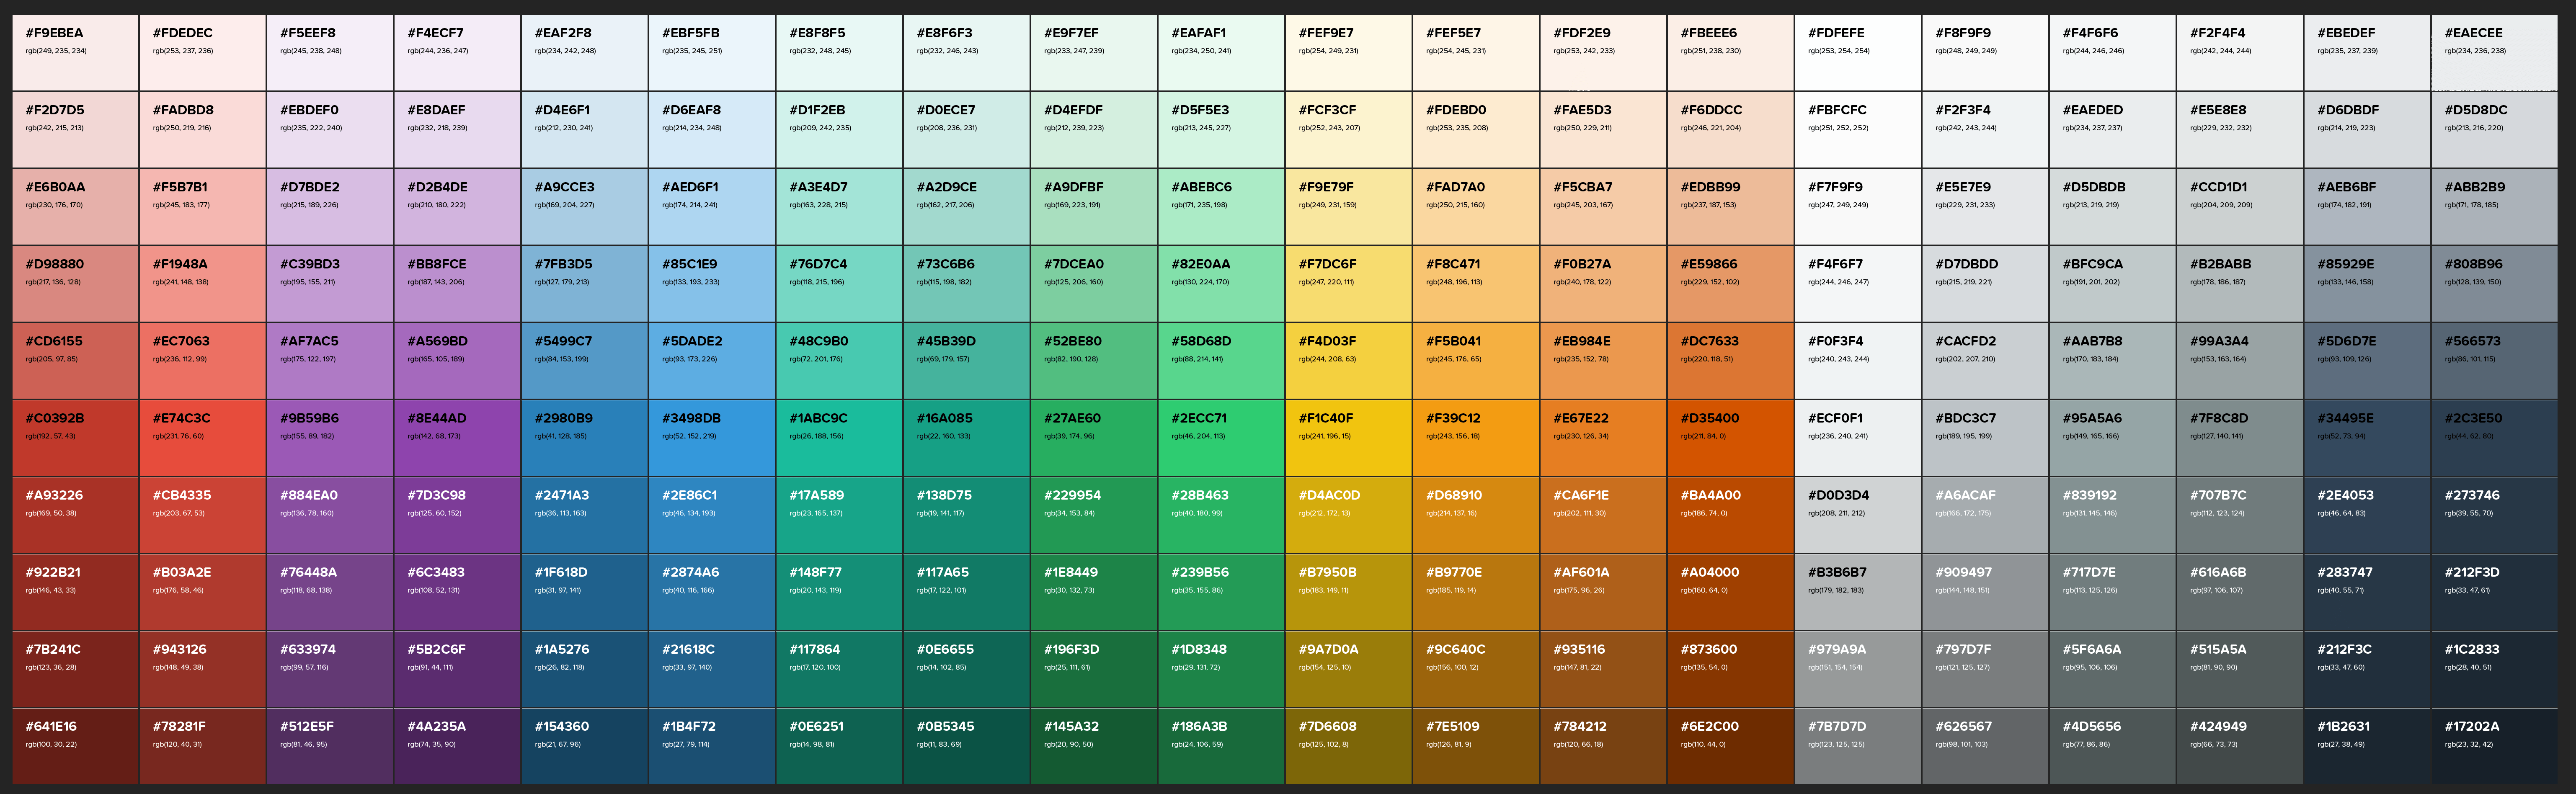
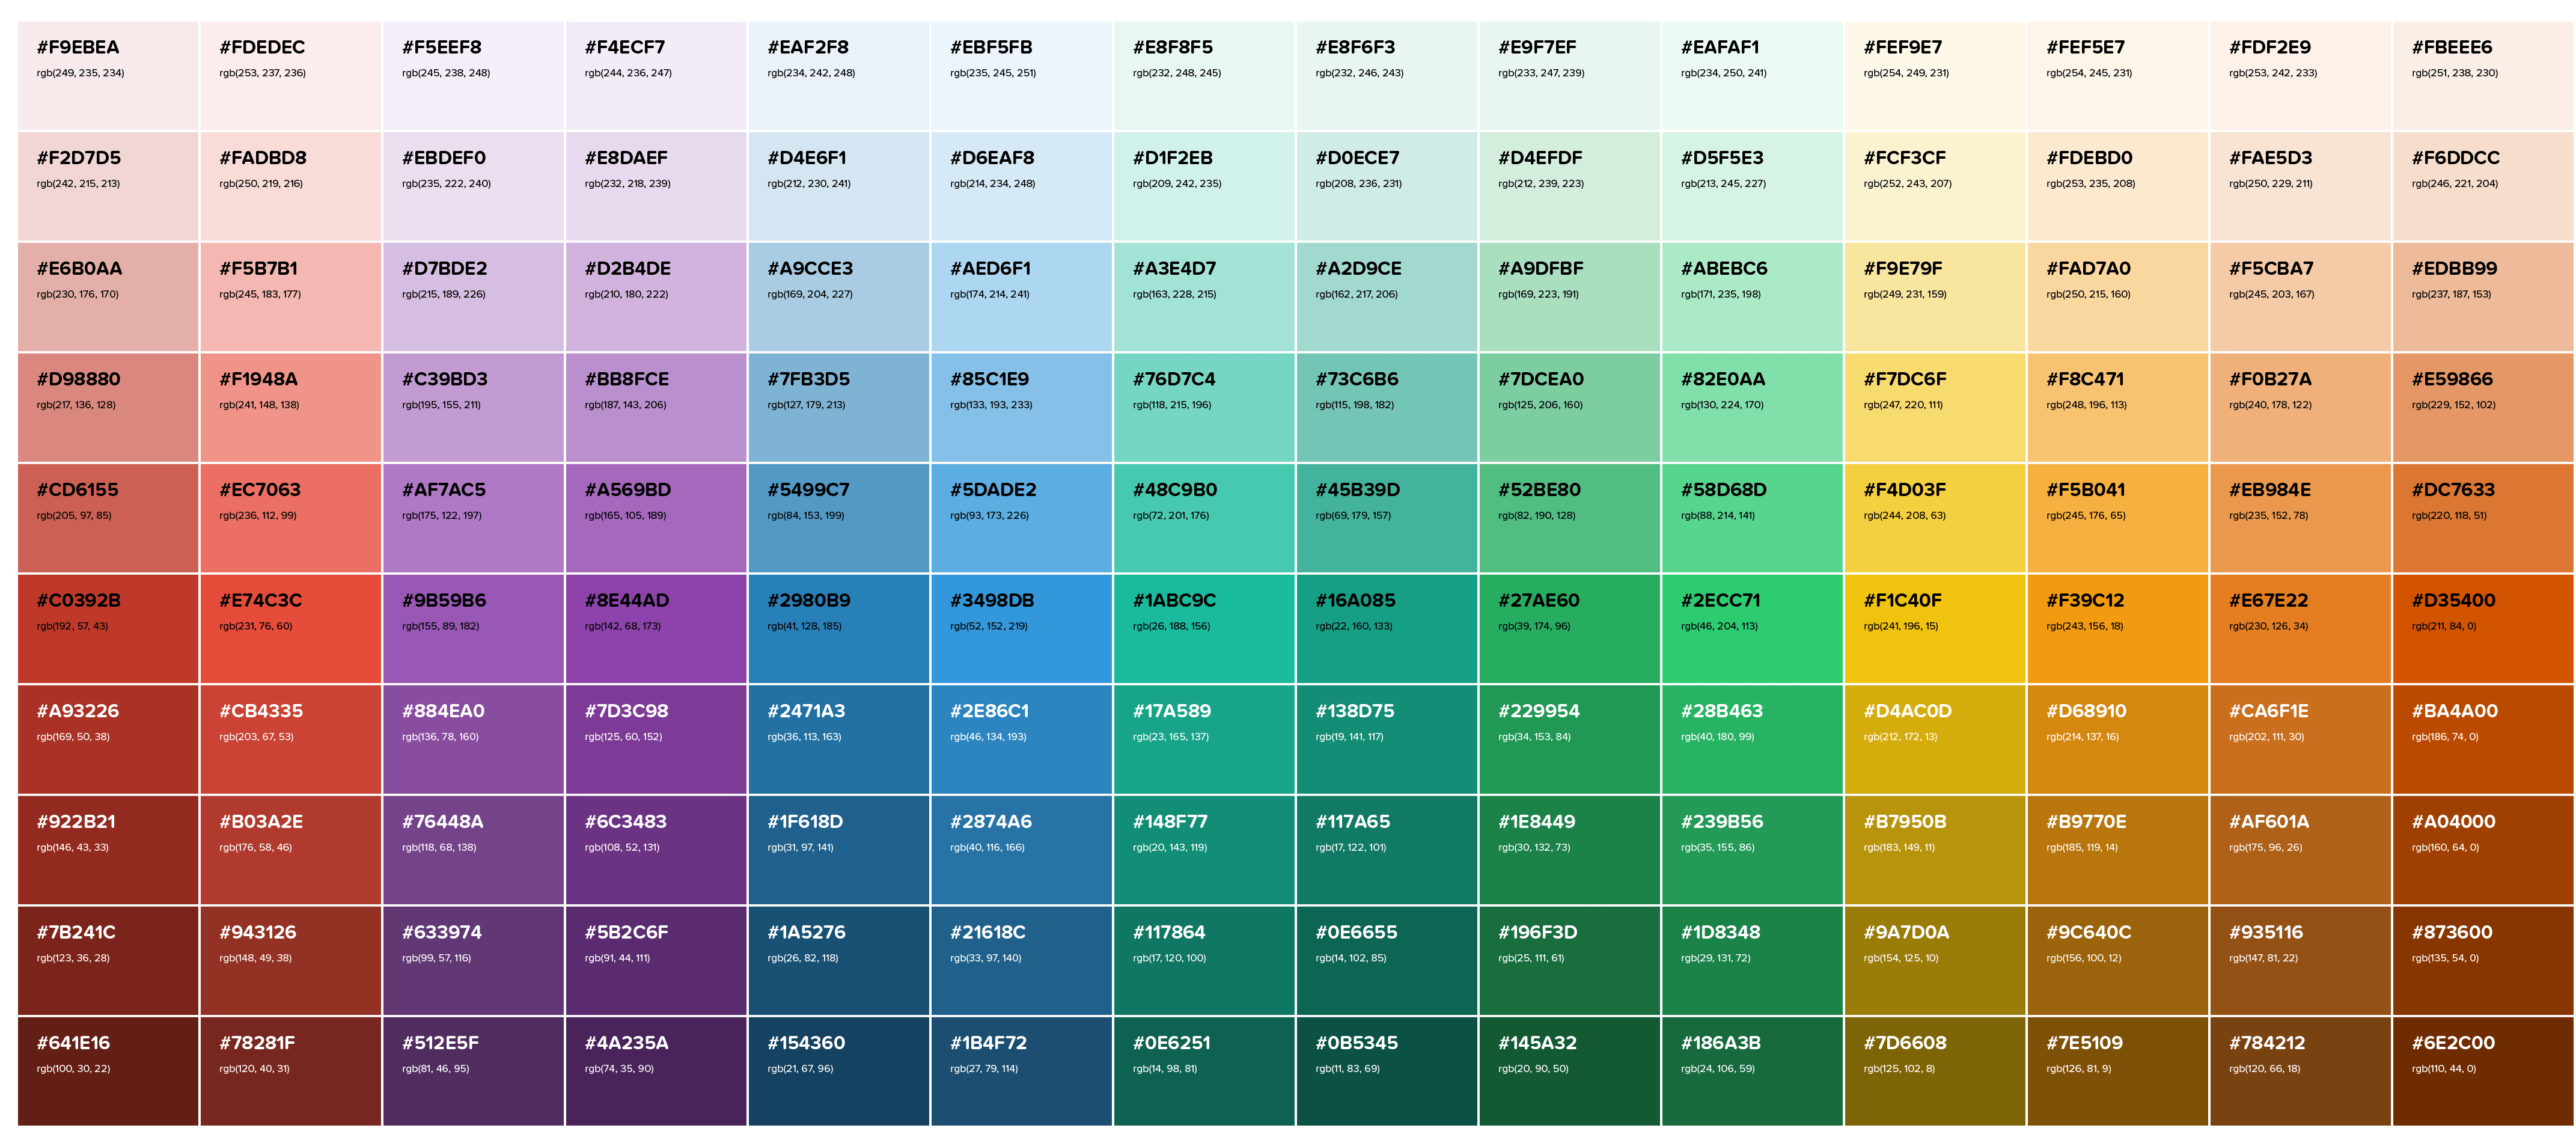

In [108]:
%matplotlib inline

import os
from time import time
import scipy.stats
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['figure.facecolor'] = '#242424'
plt.rcParams['axes.facecolor'] = '#242424'

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, \
                                          QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegressionCV
from sklearn.svm import LinearSVC, SVC

from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, \
                             AdaBoostClassifier, GradientBoostingClassifier

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import KFold, GridSearchCV, RandomizedSearchCV, train_test_split, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=598)

# from sklearn.metrics import mean_squared_error as skl_metrics_mse
# from sklearn import tree
# from sklearn.model_selection import KFold, cross_val_score
# from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
# from sklearn.linear_model import LinearRegression, Ridge
# from sklearn.preprocessing import StandardScaler

Kepler Objects of Interest (KOIs) from the NASA Exoplanet Archive cumulative table.  
[NASA Exoplanet Archive, cumulative KOI table](https://exoplanetarchive.ipac.caltech.edu)  
Each row is a transit-like signal around a Kepler star. The archive labels the object as CONFIRMED (published planet), FALSE POSITIVE (the transit is not a planet), or CANDIDATE (still under review).

Do the transit geometry and the host-star properties, by themselves, distinguish confirmed planets from false positives?  
Which classifier from the course you would trust for that triage

Design a fair comparison of classifiers for this two-class problem.  
The comparison has to be something you could defend to an astronomer who will spend telescope time on the objects you call planets.

## <span style="color: dodgerblue">retrieval and storage

In [2]:
NOTEBOOK_DIR = os.path.dirname(os.path.abspath("__file__"))

In [3]:
df_raw = pd.read_csv(os.path.join(NOTEBOOK_DIR, "source_data", "kepler_koi.csv"))

In [ ]:
df_raw

In [20]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7587 entries, 0 to 7586
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   kepoi_name       7587 non-null   object 
 1   koi_disposition  7587 non-null   object 
 2   koi_period       7587 non-null   float64
 3   koi_duration     7587 non-null   float64
 4   koi_depth        7328 non-null   float64
 5   koi_impact       7328 non-null   float64
 6   koi_model_snr    7328 non-null   float64
 7   koi_prad         7328 non-null   float64
 8   koi_teq          7328 non-null   float64
 9   koi_insol        7368 non-null   float64
 10  koi_sma          7328 non-null   float64
 11  koi_incl         7327 non-null   float64
 12  koi_ror          7328 non-null   float64
 13  koi_steff        7328 non-null   float64
 14  koi_slogg        7328 non-null   float64
 15  koi_srad         7328 non-null   float64
 16  koi_smass        7328 non-null   float64
 17  koi_smet      

In [15]:
df_raw.columns

Index(['kepoi_name', 'koi_disposition', 'koi_period', 'koi_duration',
       'koi_depth', 'koi_impact', 'koi_model_snr', 'koi_prad', 'koi_teq',
       'koi_insol', 'koi_sma', 'koi_incl', 'koi_ror', 'koi_steff', 'koi_slogg',
       'koi_srad', 'koi_smass', 'koi_smet', 'koi_kepmag', 'koi_srho'],
      dtype='object')

In [366]:
df_raw["koi_disposition"]

0            CONFIRMED
1            CONFIRMED
2            CONFIRMED
3            CONFIRMED
4            CONFIRMED
             ...      
7582    FALSE POSITIVE
7583    FALSE POSITIVE
7584    FALSE POSITIVE
7585    FALSE POSITIVE
7586    FALSE POSITIVE
Name: koi_disposition, Length: 7587, dtype: object

## preprocessing

The file has n = 7587 objects (2748 CONFIRMED, 4839 FALSE POSITIVE).

### <span style="color: mediumspringgreen"> **Test/train split**

In [223]:
X = df_raw.drop(columns=["kepoi_name", "koi_disposition"])
Y = df_raw["koi_disposition"]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y,
                                                    test_size=0.3,
                                                    random_state=598,
                                                    stratify=Y)
display(f"X_train shape: {X_train.shape}")
display(f"X_test shape: {X_test.shape}")
display(f"Y_train shape: {Y_train.shape}")
display(f"Y_test shape: {Y_test.shape}")

'X_train shape: (5310, 18)'

'X_test shape: (2277, 18)'

'Y_train shape: (5310,)'

'Y_test shape: (2277,)'

### Explore missing values

Missing values: drop or impute using training-set information only; explain what you did.

In [31]:
# any missing data in the response variable?
display(Y_train.isna().any())
display(Y_test.isna().any())

False

False

> no

In [159]:
# missing values per column
X_train.isna().sum()

koi_period         0
koi_duration       0
koi_depth        186
koi_impact       186
koi_model_snr    186
koi_prad         186
koi_teq          186
koi_insol        158
koi_sma          186
koi_incl         186
koi_ror          186
koi_steff        186
koi_slogg        186
koi_srad         186
koi_smass        186
koi_smet         198
koi_kepmag         1
koi_srho         158
dtype: int64

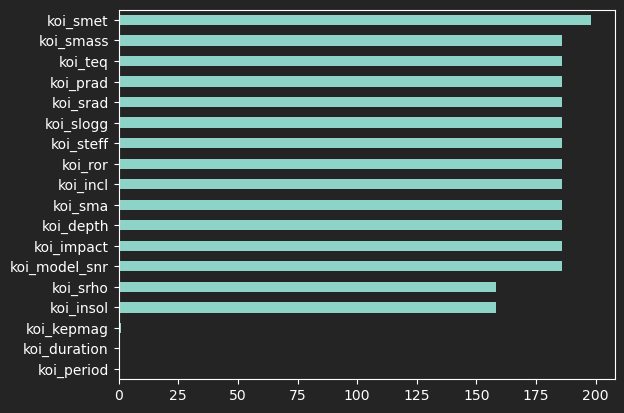

In [69]:
# Missing values in each column
X_train.isna().sum(axis=0).sort_values().plot(kind="barh");

In [38]:
X_train.head()

,koi_period,koi_duration,koi_depth,koi_impact,koi_model_snr,koi_prad,koi_teq,koi_insol,koi_sma,koi_incl,koi_ror,koi_steff,koi_slogg,koi_srad,koi_smass,koi_smet,koi_kepmag,koi_srho
2893,20.131478,3.28060,8243.2,1.279,427.5,39.89,670.0,47.49,0.1458,87.15,0.391955,6003.0,4.507,0.932,1.019,-0.14,14.519,0.79745
4991,3.556619,5.39600,23.3,0.384,11.4,0.72,1518.0,1254.47,0.0446,85.33,0.004492,6018.0,4.081,1.458,0.934,-0.42,12.840,0.15725
7049,12.822525,18.80000,19268.0,0.706,13.7,20.12,915.0,165.54,0.1074,84.75,0.136252,5845.0,4.178,1.352,1.003,NaN,11.863,0.05290
7450,381.858520,16.12100,362.9,0.024,16.0,8.30,453.0,9.93,1.0472,89.99,0.016941,4959.0,3.155,4.486,1.049,-0.26,12.883,0.80777
4470,0.798197,2.22035,257616.0,0.670,453.9,62.38,1963.0,3497.40,0.0169,80.47,0.571257,5780.0,4.438,1.000,1.000,0.00,17.579,1.96762


In [132]:
# number and proportion of rows w/ at least one missing value - TRAIN
display(f"{X_train.isna().any(axis=1).mean() * 100 :.2f}% ({X_train.isna().any(axis=1).sum()} of {X_train.shape[0]}) missing (TRAIN)")
# number and proportion of rows w/ at least one missing value - TEST
display(f"{X_test.isna().any(axis=1).mean() * 100 :.2f}% ({X_test.isna().any(axis=1).sum()} of {X_test.shape[0]}) missing (TEST)")

'3.75% (199 of 5310) missing (TRAIN)'

'3.60% (82 of 2277) missing (TEST)'

In [22]:
# Rows that have at least one missing value
X_train[X_train.isna().any(axis=1)]

,koi_period,koi_duration,koi_depth,koi_impact,koi_model_snr,koi_prad,koi_teq,koi_insol,koi_sma,koi_incl,koi_ror,koi_steff,koi_slogg,koi_srad,koi_smass,koi_smet,koi_kepmag,koi_srho
7049,12.822525,18.800,19268.0,0.7060,13.7,20.12,915.0,165.54,0.1074,84.75,0.136252,5845.0,4.178,1.352,1.003,NaN,11.863,0.05290
5524,37.476957,1.460,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.508,NaN
4836,72.563291,3.088,332.3,0.4863,6.4,1.99,436.0,8.58,0.3412,89.95,0.018229,5780.0,4.438,1.000,1.000,NaN,13.482,14.87927
4835,28.546357,9.290,153.3,0.2411,10.1,1.35,596.0,29.76,0.1832,89.38,0.012382,5780.0,4.438,1.000,1.000,NaN,13.482,0.28619
5591,2.164027,2.780,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.090,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5197,43.227931,1.390,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.654,NaN
5206,225.434204,13.020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.166,NaN
6667,1.254518,2.640,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.525,NaN
3947,0.636244,4.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.290,NaN


In [187]:
# Missing values per row/entry (only rows w/ missing values)
X_train[X_train.isna().any(axis=1)].isna().sum(axis=1)

7049     1
5524    15
4836     1
4835     1
5591    15
        ..
5197    15
5206    15
6667    15
3947    15
5174    15
Length: 199, dtype: int64

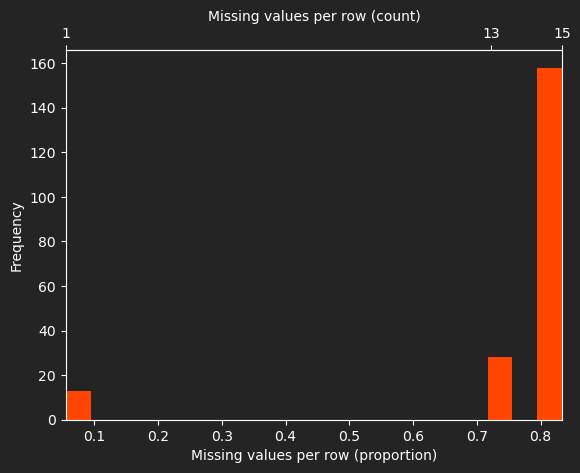

In [183]:
# distribution of missing values per row that has any value missing

missing_mask = X_train.isna().any(axis=1)
missing_counts = X_train[missing_mask].isna().sum(axis=1)
n_features = X_train.shape[1]

fig, ax_prop = plt.subplots()
plt.sca(ax_prop)  # make sure the histogram below is drawn on this axis

ax_prop.set_xlabel("Missing values per row (proportion)")
ax_prop.set_ylabel("Frequency")
ax_prop.set_xlim(missing_counts.min() / n_features, missing_counts.max() / n_features)

ax_count = ax_prop.secondary_xaxis(
    "top",
    functions=(lambda p: p * n_features, lambda c: c / n_features)
)
ax_count.set_xlabel("Missing values per row (count)")
ax_count.set_xticks(np.unique(missing_counts))


X_train[X_train.isna().any(axis=1)].isna().mean(axis=1).hist(grid=False, bins=20, color="orangered");

koi period and duration are always present. Can they serve by themselves as useful predictors for the rows with missing values?

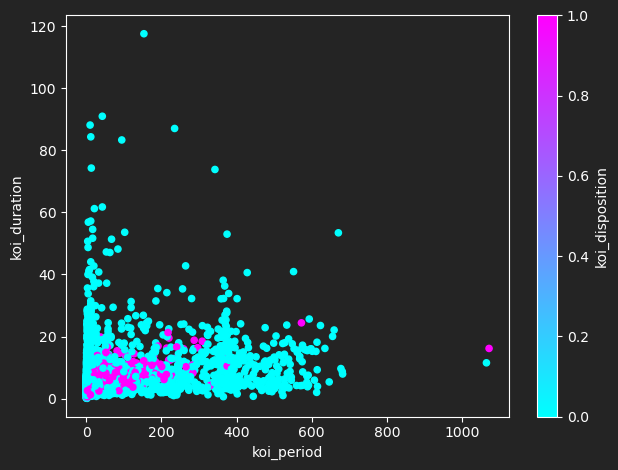

In [178]:
# see if koi_period and koi_duration by themselves show useful separation
X_train.join(Y_train.eq("CONFIRMED").astype("int")).plot.scatter(x = "koi_period", y= "koi_duration", c = "koi_disposition", colormap="cool");
plt.tight_layout()

> not really

koi_kepmag is almost always present. Maybe we using it with one of the others provides a useful discrimination

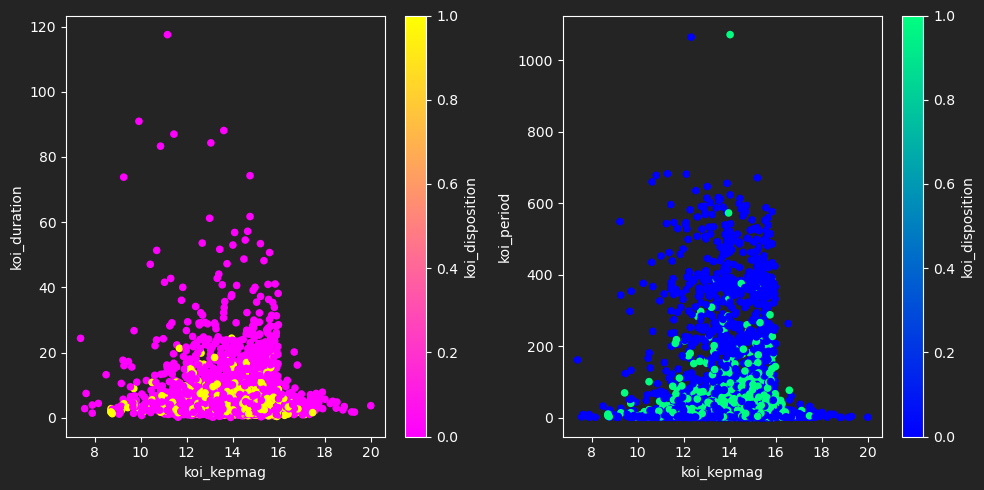

In [185]:
# see if koi_kepmag with either koi_period or koi_duration shows useful separation
fig, ax = plt.subplots(1, 2)
fig.set_size_inches(10, 5)
X_train.join(Y_train.eq("CONFIRMED").astype("int")).plot.scatter(x = "koi_kepmag", y= "koi_duration", c = "koi_disposition", colormap="spring", ax=ax[0]);
X_train.join(Y_train.eq("CONFIRMED").astype("int")).plot.scatter(x = "koi_kepmag", y= "koi_period", c = "koi_disposition", colormap="winter", ax=ax[1]);
plt.tight_layout()

> not really

I decided to exclude the records with 15/18 missing feature values. Recovery of those training samples via imputation would yield almost entirely-artificial "observations".  
For the records with only 1 missing value, I 

In [341]:
X_train[(X_train.isna().sum(axis=1) > 5)]

,koi_period,koi_duration,koi_depth,koi_impact,koi_model_snr,koi_prad,koi_teq,koi_insol,koi_sma,koi_incl,koi_ror,koi_steff,koi_slogg,koi_srad,koi_smass,koi_smet,koi_kepmag,koi_srho
5524,37.476957,1.46,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.508,NaN
5591,2.164027,2.78,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.090,NaN
4859,42.624233,1.47,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.981,NaN
5397,43.600125,1.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.385,NaN
5901,13.599401,2.52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.191,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5197,43.227931,1.39,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.654,NaN
5206,225.434204,13.02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.166,NaN
6667,1.254518,2.64,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.525,NaN
3947,0.636244,4.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.290,NaN


In [345]:
# rows with a reasonable number of missing values
missing_rows = X_train[X_train.isna().any(axis=1) & (X_train.isna().sum(axis=1) < 5)]; missing_rows

,koi_period,koi_duration,koi_depth,koi_impact,koi_model_snr,koi_prad,koi_teq,koi_insol,koi_sma,koi_incl,koi_ror,koi_steff,koi_slogg,koi_srad,koi_smass,koi_smet,koi_kepmag,koi_srho
7049,12.822525,18.8000,19268.0,0.7060,13.7,20.12,915.0,165.54,0.1074,84.75,0.136252,5845.0,4.178,1.352,1.003,NaN,11.863,0.05290
4836,72.563291,3.0880,332.3,0.4863,6.4,1.99,436.0,8.58,0.3412,89.95,0.018229,5780.0,4.438,1.000,1.000,NaN,13.482,14.87927
4835,28.546357,9.2900,153.3,0.2411,10.1,1.35,596.0,29.76,0.1832,89.38,0.012382,5780.0,4.438,1.000,1.000,NaN,13.482,0.28619
5364,246.121740,18.0000,6847.0,67.1930,9.2,7233.87,291.0,1.68,0.7702,76.20,66.244209,5780.0,4.438,1.000,1.000,NaN,13.671,7.01276
5635,247.372131,3.2710,513.4,0.4257,12.4,2.47,290.0,1.67,0.7729,89.95,0.022658,5780.0,4.438,1.000,1.000,NaN,13.359,47.93930
3967,6.558835,3.0340,41.2,0.7173,8.1,0.70,973.0,211.64,0.0687,86.52,0.006416,5780.0,4.438,1.000,1.000,NaN,10.609,0.70207
7176,4.753079,2.3500,933.0,0.0190,6.4,505.94,7040.0,580415.20,0.0859,89.83,0.025738,3486.0,0.500,180.013,3.735,NaN,13.524,0.20370
4832,36.616669,8.6200,237.4,0.3646,3.4,1.68,548.0,21.35,0.2163,89.38,0.015407,5780.0,4.438,1.000,1.000,NaN,13.482,0.41086
7527,307.947357,15.0000,11296.0,0.9660,16.5,76.66,492.0,13.83,0.8540,88.17,0.157367,4878.0,3.080,4.461,0.874,NaN,14.092,0.00554
6452,548.084410,17.6600,560.0,0.1531,7.4,2.35,222.0,0.58,1.3135,89.95,0.021508,5780.0,4.438,1.000,1.000,NaN,9.233,0.86399


I decided to exclude the records with 15/18 missing feature values. Recovery of those training samples via imputation would yield almost entirely-artificial "observations".  
For the records with only 1 missing value, I 

In [212]:
# Missing values in each column of this subset
missing_rows.isna().sum(axis=0)[missing_rows.isna().sum(axis=0).gt(0)]

koi_smet      12
koi_kepmag     1
dtype: int64

In [351]:
# keep only rows with 5 or fewer missing values
keep_mask_train = X_train.isna().sum(axis=1) <= 5
X_train = X_train.loc[keep_mask_train].copy()
Y_train = Y_train.loc[keep_mask_train].copy()  # keep labels aligned

keep_mask_test = X_test.isna().sum(axis=1) <= 5
X_test = X_test.loc[keep_mask_test].copy()
Y_test = Y_test.loc[keep_mask_test].copy()  # keep labels aligned

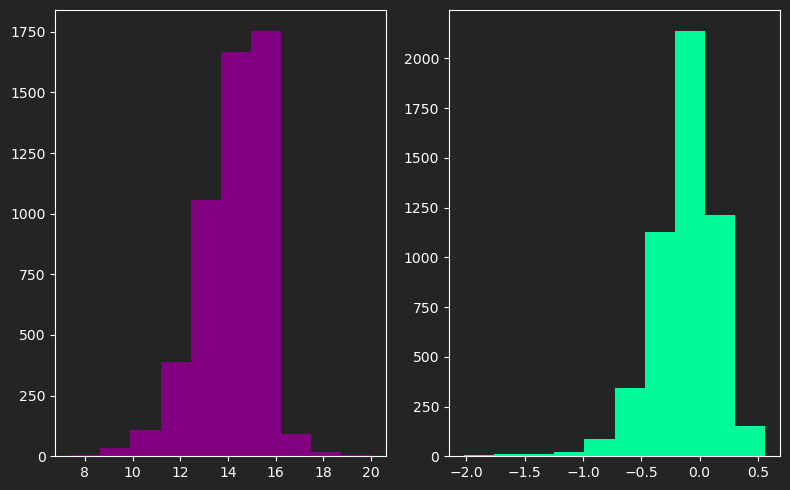

In [352]:
# now let's see what the distribution of this column's values look like
fig, ax = plt.subplots(1, 2)
fig.set_size_inches(8, 5)
X_train["koi_kepmag"].hist(grid=False, ax = ax[0], color="purple");
X_train["koi_smet"].hist(grid=False, ax = ax[1], color="mediumspringgreen");
plt.tight_layout()

> unimodal, not quite normal but relatively well-behaved  
quite peaked, so using the median should be a good substitute

### <span style="color: mediumspringgreen"> **Drop rows and impute values**

See above for reasoning

In [224]:
# keep only rows with 5 or fewer missing values
keep_mask_train = X_train.isna().sum(axis=1) <= 5
X_train = X_train.loc[keep_mask_train].copy()
Y_train = Y_train.loc[keep_mask_train].copy()

keep_mask_test = X_test.isna().sum(axis=1) <= 5
X_test = X_test.loc[keep_mask_test].copy()
Y_test = Y_test.loc[keep_mask_test].copy()

In [225]:
# for any missing values now, use the median of that feature's distribution 
# using training-data distribution only
feature_cols = X_train.columns
imputer = SimpleImputer(strategy="median")
imputer.fit(X_train[feature_cols])
X_train = pd.DataFrame(imputer.transform(X_train[feature_cols]), columns=feature_cols, index=X_train.index)
X_test  = pd.DataFrame(imputer.transform(X_test[feature_cols]),  columns=feature_cols, index=X_test.index)

## EDA

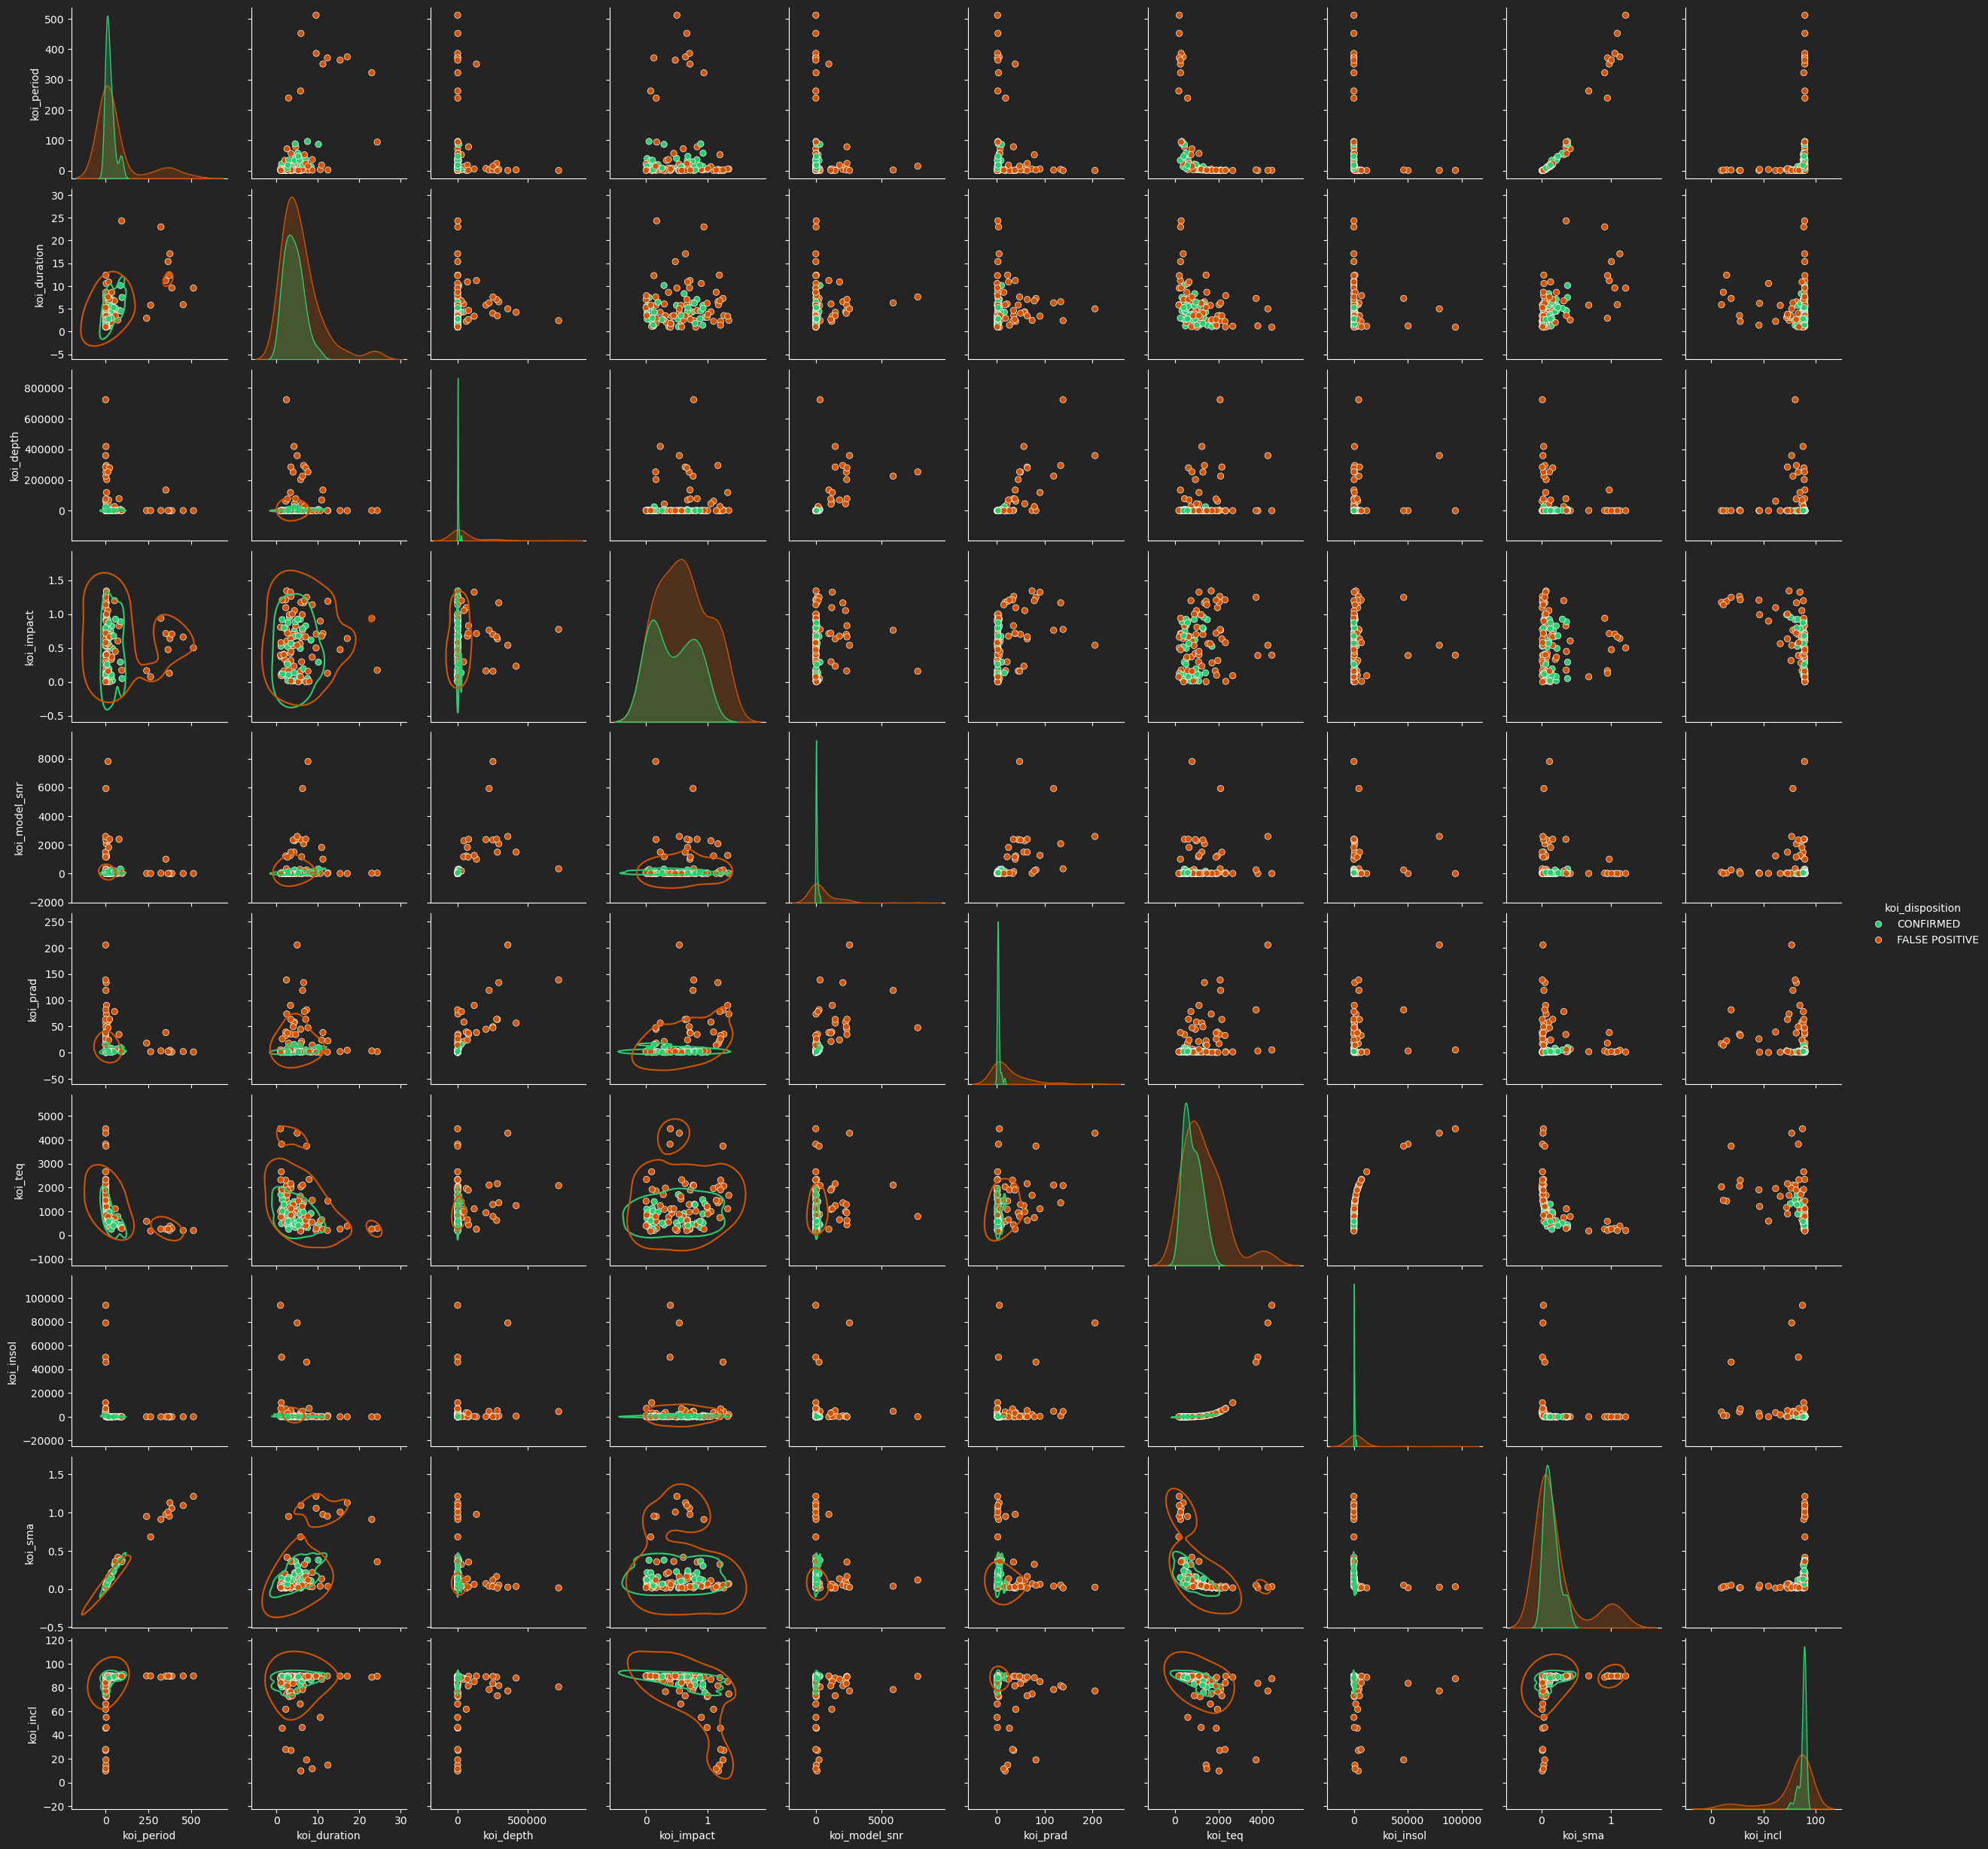

In [ ]:
import seaborn as sns
g = sns.pairplot(X_train.iloc[:, :10].join(Y_train).sample(n=100, random_state=598),
                 hue="koi_disposition",
                 hue_order=["CONFIRMED", "FALSE POSITIVE"],
                 palette=["#2ecc71", "#d35400"])
# overlay gaussian cluster contour lines
g.map_lower(sns.kdeplot, levels=2, color=".2");

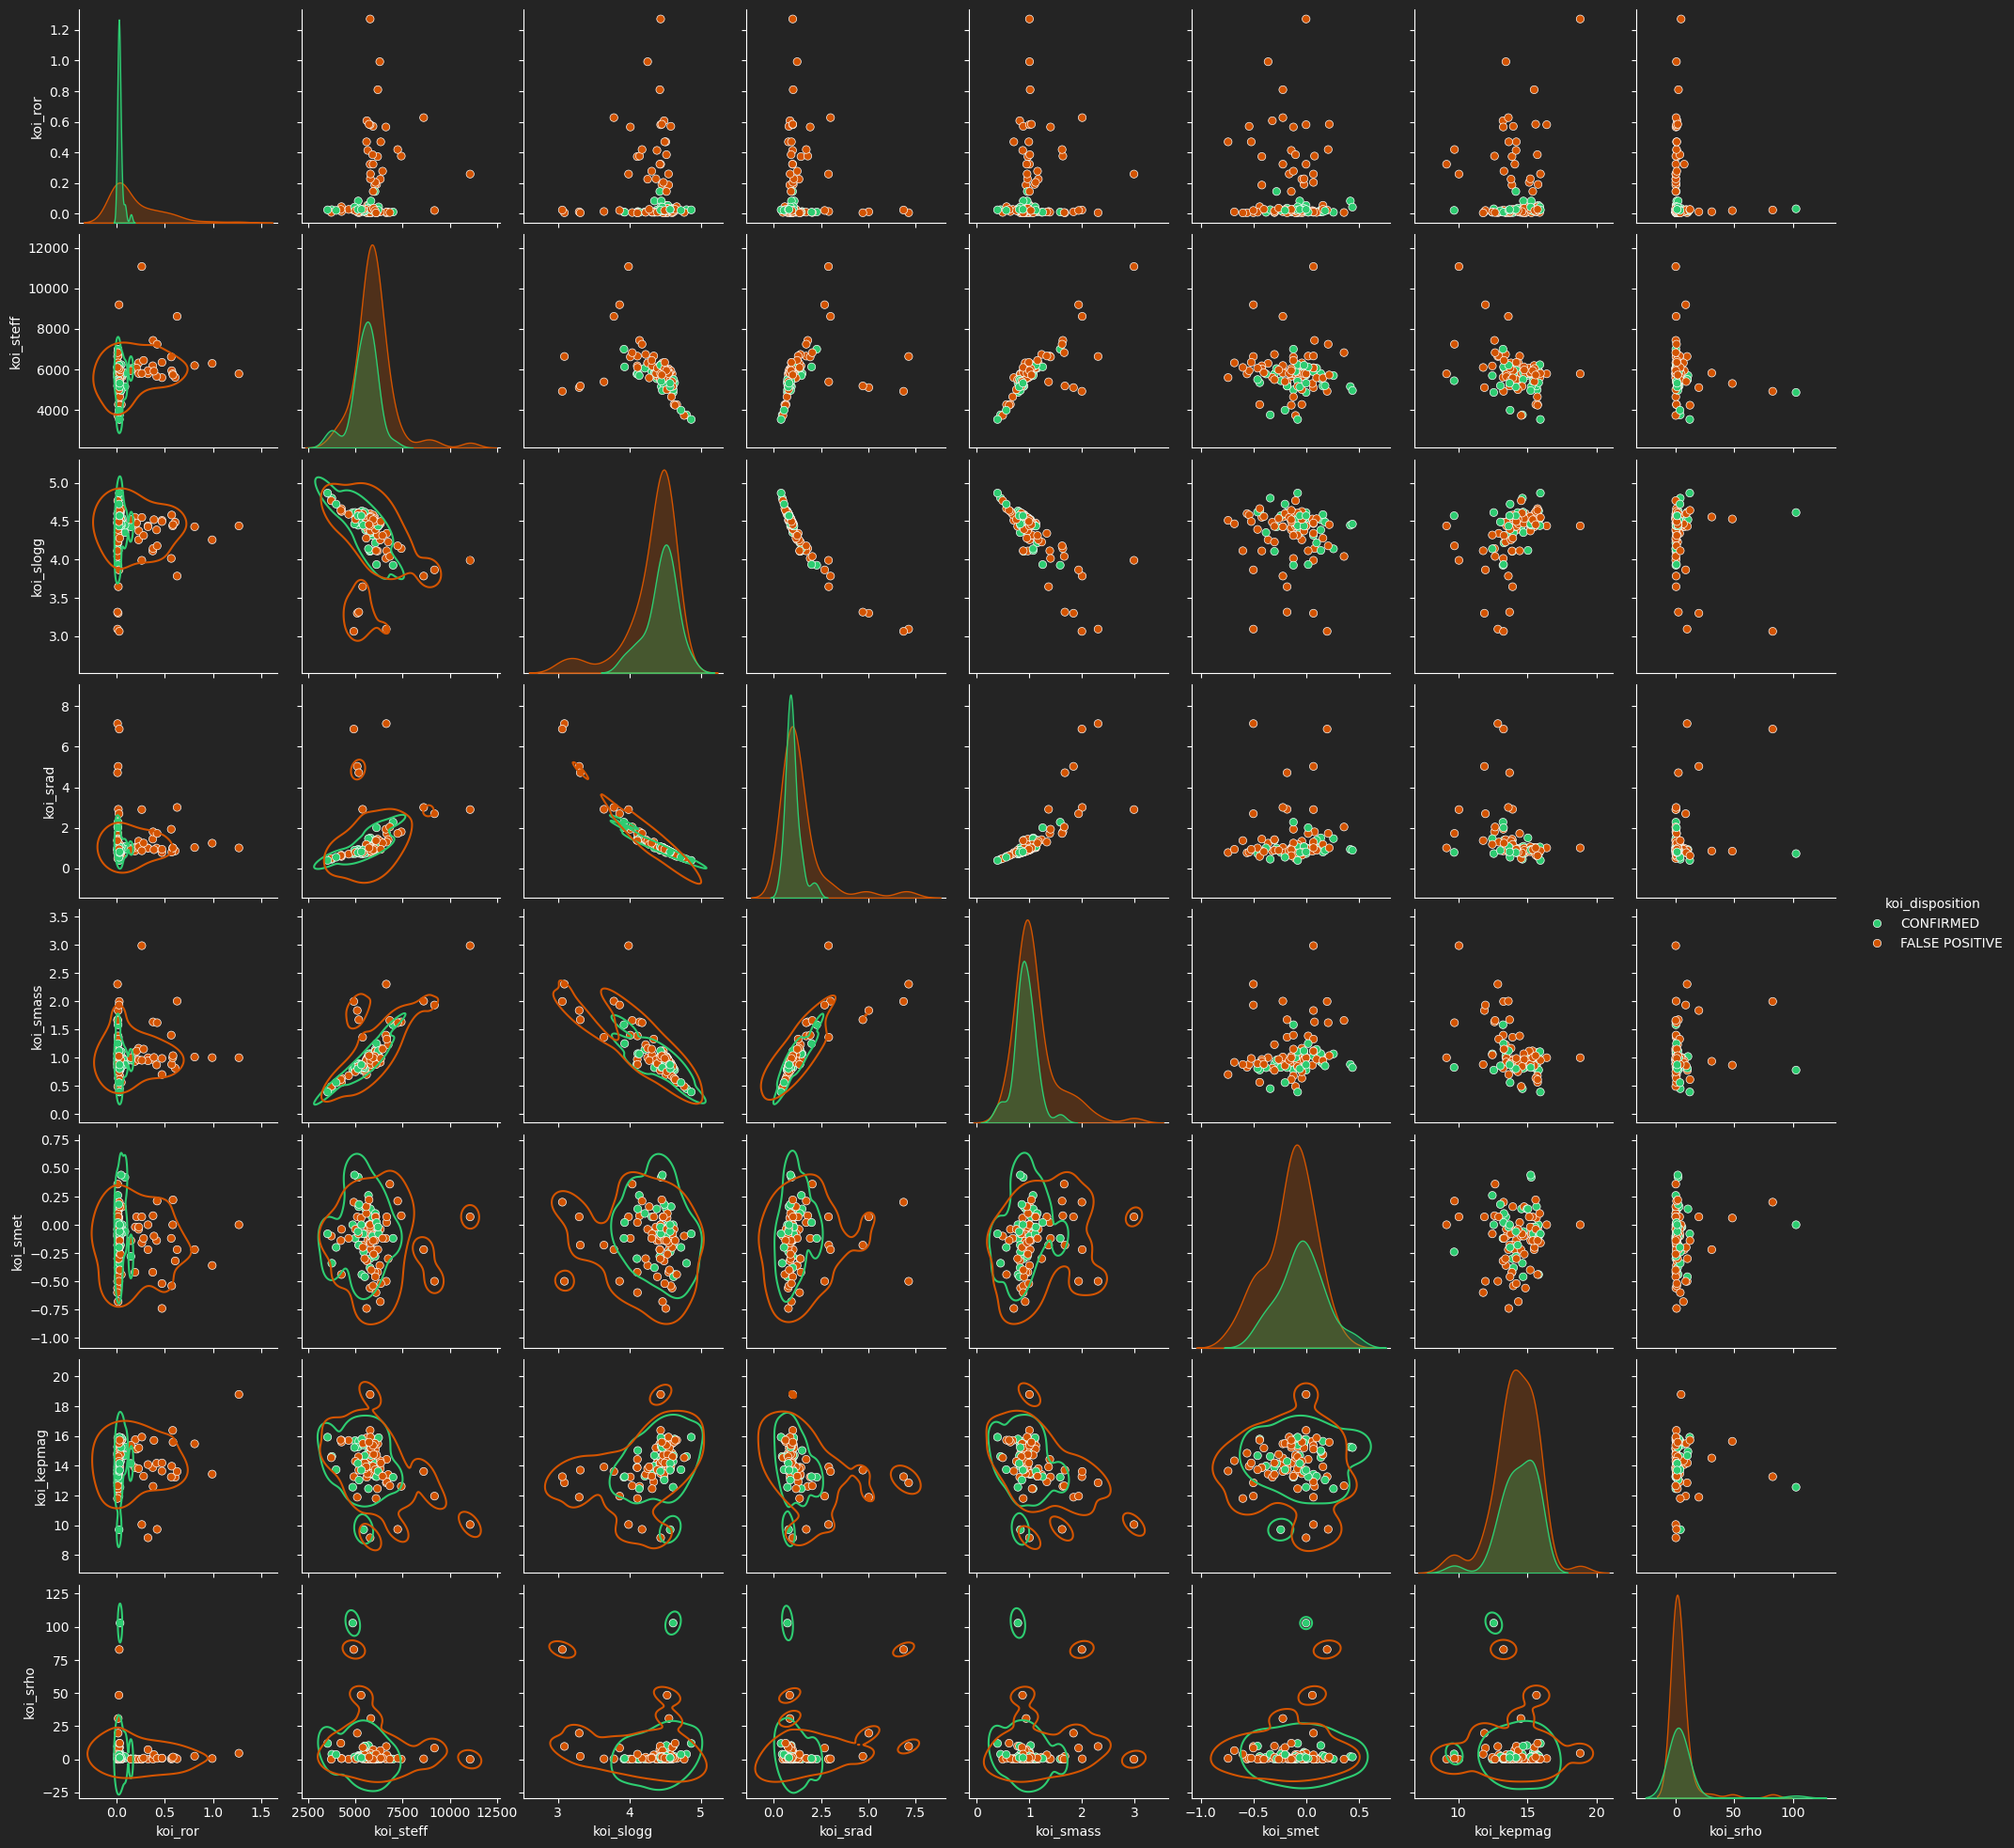

In [ ]:
import seaborn as sns
g = sns.pairplot(X_train.iloc[:, 10:].join(Y_train).sample(n=100, random_state=598),
                 hue="koi_disposition",
                 hue_order=["CONFIRMED", "FALSE POSITIVE"],
                 palette=["#2ecc71", "#d35400"])
# overlay gaussian cluster contour lines
g.map_lower(sns.kdeplot, levels=2, color=".2");

## LDA

In [215]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda_model = LinearDiscriminantAnalysis()
lda_model = make_pipeline(
                        StandardScaler(),
                        LinearDiscriminantAnalysis())
lda_model.fit(X_train, Y_train)
lda_model.score(X_train, Y_train)

0.8317720530835285

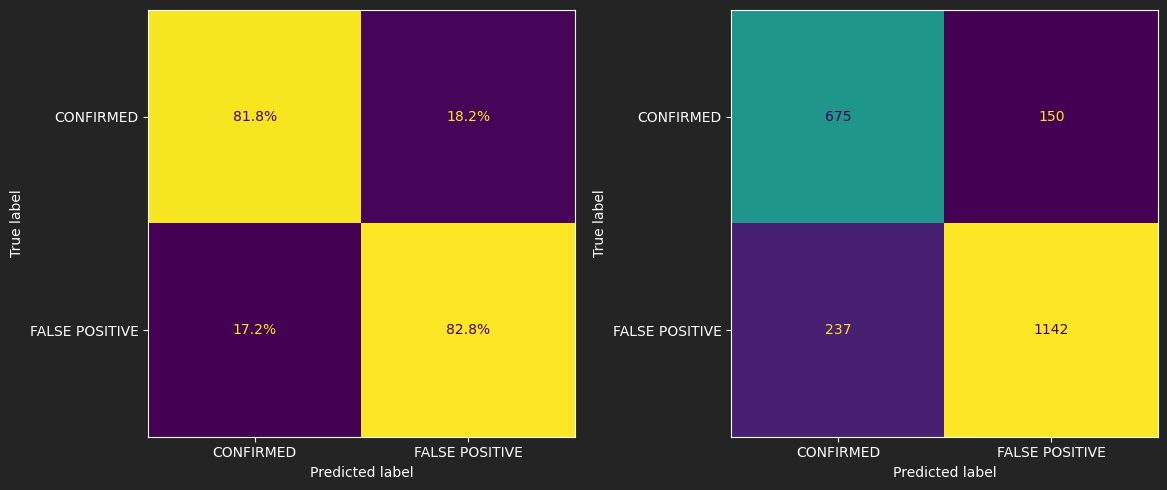

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
   Y_test, lda_model.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   normalize="true", values_format=".1%",
   ax=axes[0]
)
ConfusionMatrixDisplay.from_predictions(
   Y_test, lda_model.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   ax=axes[1]
)
plt.tight_layout();

In [228]:
Y_test == "CONFIRMED"

2050     True
6861    False
7430    False
6327    False
3720    False
        ...  
1138     True
6502    False
6356    False
5053    False
1225     True
Name: koi_disposition, Length: 2204, dtype: bool

In [ ]:
# False positives
# "False positive" bodies called confirmed planets by the classifier
f"{((Y_test != lda_model.predict(X_test))[Y_test == "FALSE POSITIVE"].mean() * 100).round(1)}%"

'17.2%'

In [ ]:
# False negatives
# Confirmed planets called "false positives" by the classifier
f"{((Y_test != lda_model.predict(X_test))[Y_test == "CONFIRMED"].mean() * 100).round(1)}%"

'18.2%'

## Logistic Regression

In [ ]:
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

In [212]:
from sklearn.linear_model import LogisticRegression

# logreg_model = LogisticRegression(random_state=598) # convergence problem
logreg_model = make_pipeline(
                        StandardScaler(),
                        LogisticRegression(random_state=598))
logreg_model.fit(X_train, Y_train)
logreg_model.score(X_train, Y_train)

0.8633879781420765

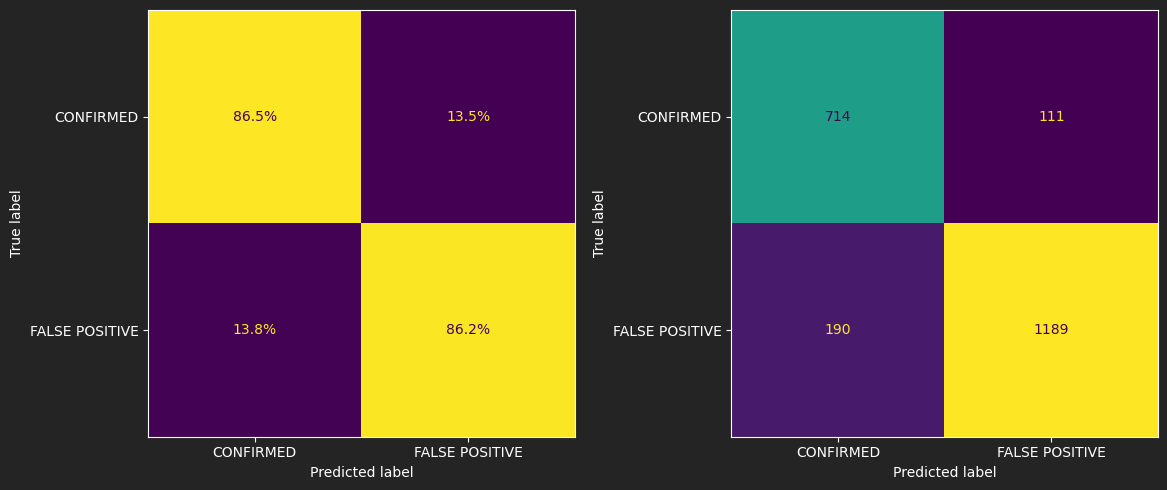

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
   Y_test, logreg_model.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   normalize="true", values_format=".1%",
   ax=axes[0]
)
ConfusionMatrixDisplay.from_predictions(
   Y_test, logreg_model.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   ax=axes[1]
)
plt.tight_layout();

In [257]:
# False positives
# "False positive" bodies called confirmed planets by the classifier
f"{((Y_test != logreg_model.predict(X_test))[Y_test == "FALSE POSITIVE"].mean() * 100).round(1)}%"

'13.8%'

In [258]:
# False negatives
# Confirmed planets called "false positives" by the classifier
f"{((Y_test != logreg_model.predict(X_test))[Y_test == "CONFIRMED"].mean() * 100).round(1)}%"

'13.5%'

## SVM - linear

In [145]:
# https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html#sklearn.svm.LinearSVC

svm_linear = make_pipeline(StandardScaler(),
                           LinearSVC(penalty="l2",
                                     dual=False,           # had to set this false to achieve convergence
                                     random_state=598))

svm_linear.fit(X_train, Y_train)
display(svm_linear.score(X_train, Y_train))
cross_val_score(svm_linear, X_train, Y_train,
                cv=kf, scoring="accuracy").mean()
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDClassifier.html#sklearn.linear_model.SGDClassifier
# For best results using the default learning rate schedule, the data should have zero mean and unit variance.

0.868071818891491

0.8655373475609757

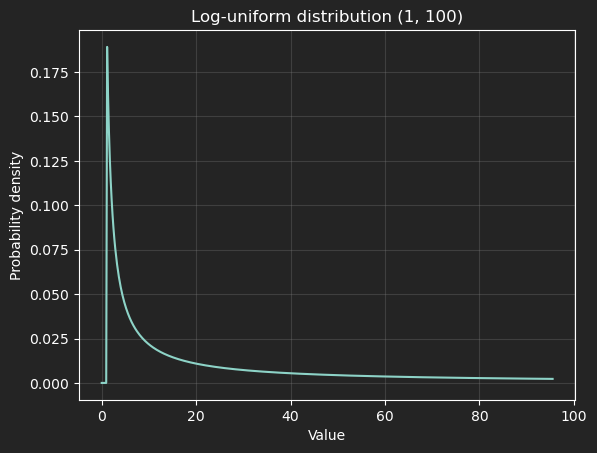

In [ ]:
# distribution to use for the hyperparameter C search
dist = scipy.stats.loguniform(1, 100)
x = np.linspace(0, dist.ppf(0.99), 500)

plt.plot(x, dist.pdf(x))
plt.xlabel("Value")
plt.ylabel("Probability density")
plt.title("Log-uniform distribution (1, 100)")
plt.grid(True, color='grey', alpha=0.3);
# {'C': scipy.stats.loguniform(1, 100)}

### C hyperparameter search

In [171]:
C_grid = {'linearsvc__C': scipy.stats.loguniform(1, 100)}

svm_linear_C_search = RandomizedSearchCV(
    estimator=svm_linear,
    param_distributions=C_grid,
    n_iter=40,
    random_state=598,
    n_jobs=2,
    verbose=1,
    cv=kf
)

svm_linear_C_search.fit(X_train, Y_train)
best_parameters = svm_linear_C_search.best_estimator_.get_params()
for param_name in sorted(C_grid.keys()):
    print(f"{param_name}: {best_parameters[param_name]}")
display(svm_linear_C_search.best_score_)
svm_linear_C_optimized = svm_linear_C_search.best_estimator_

Fitting 5 folds for each of 40 candidates, totalling 200 fits
linearsvc__C: 10.394034751821398


0.8680746951219511

In [173]:
display(svm_linear_C_search.best_estimator_.score(X_train, Y_train))
cross_val_score(svm_linear_C_optimized, X_train, Y_train,
                cv=kf, scoring="accuracy").mean()

0.8696330991412958

0.8680746951219511

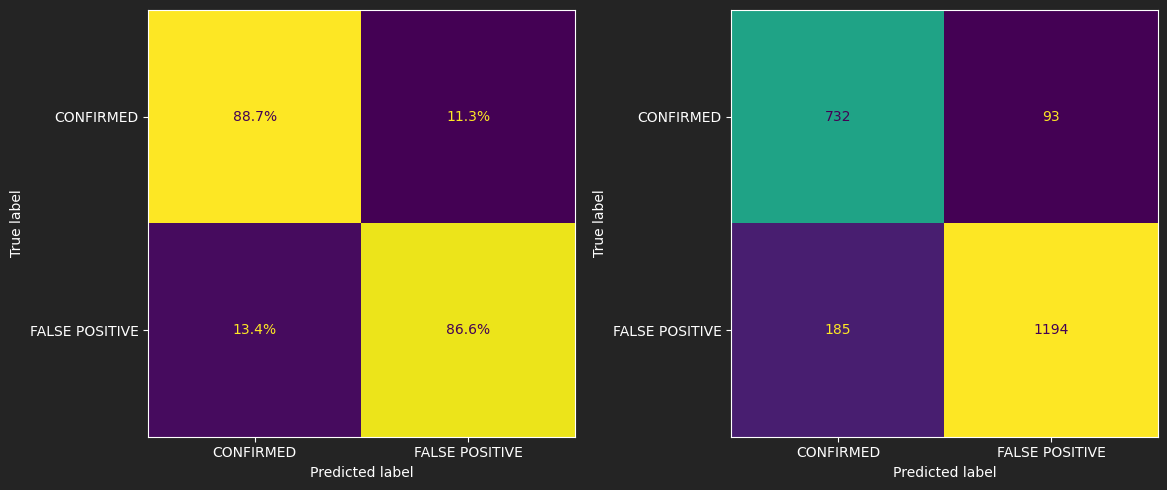

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
   Y_test, svm_linear_C_optimized.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   normalize="true", values_format=".1%",
   ax=axes[0]
)
ConfusionMatrixDisplay.from_predictions(
   Y_test, svm_linear_C_optimized.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   ax=axes[1]
)
plt.tight_layout();

In [ ]:
# False positives
# "False positive" bodies called confirmed planets by the classifier
f"{((Y_test != svm_linear_C_optimized.predict(X_test))[Y_test == "FALSE POSITIVE"].mean() * 100).round(1)}%"

'13.4%'

In [ ]:
# False negatives
# Confirmed planets called "false positives" by the classifier
f"{((Y_test != svm_linear_C_optimized.predict(X_test))[Y_test == "CONFIRMED"].mean() * 100).round(1)}%"

'11.3%'

## SVM - kernel

In [143]:
# https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC

svm_rbf = make_pipeline(StandardScaler(),
                        SVC(kernel="rbf",
                            random_state=598))
svm_rbf.fit(X_train, Y_train)

display(svm_rbf.score(X_train, Y_train))
cross_val_score(svm_rbf, X_train, Y_train,
                cv=kf, scoring="accuracy").mean()
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDClassifier.html#sklearn.linear_model.SGDClassifier
# For best results using the default learning rate schedule, the data should have zero mean and unit variance.

0.8708040593286495

0.8661208079268292

### C hyperparameter search

In [176]:
C_and_gamma_grid = {'svc__C': scipy.stats.loguniform(1, 100),
                    'svc__gamma': scipy.stats.loguniform(1e-4, 1)
                    }

svm_rbf_C_search = RandomizedSearchCV(
    estimator=svm_rbf,
    param_distributions=C_and_gamma_grid,
    n_iter=40,
    random_state=598,
    n_jobs=2,
    verbose=1,
    cv=kf
)

svm_rbf_C_search.fit(X_train, Y_train)
best_parameters = svm_rbf_C_search.best_estimator_.get_params()
for param_name in sorted(C_and_gamma_grid.keys()):
    print(f"{param_name}: {best_parameters[param_name]}")
display(svm_rbf_C_search.best_score_)
svm_rbf_C_optimized = svm_rbf_C_search.best_estimator_

Fitting 5 folds for each of 40 candidates, totalling 200 fits
svc__C: 36.7346848116416
svc__gamma: 0.05777707871296579


In [177]:
display(svm_rbf_C_optimized.score(X_train, Y_train))
cross_val_score(svm_rbf_C_optimized, X_train, Y_train,
                cv=kf, scoring="accuracy").mean()

0.9113973458235753

0.8942271341463414

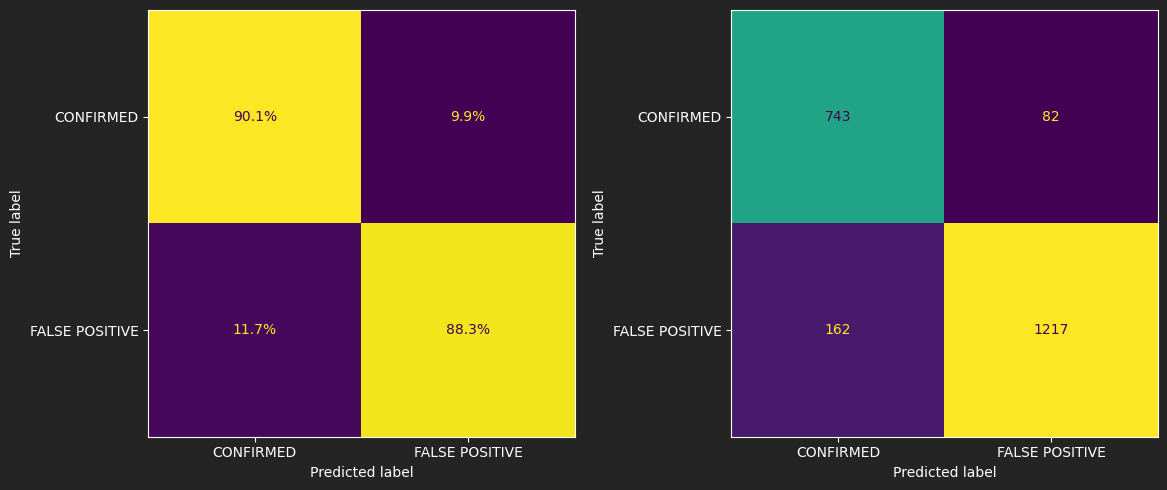

In [179]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
   Y_test, svm_rbf_C_optimized.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   normalize="true", values_format=".1%",
   ax=axes[0]
)
ConfusionMatrixDisplay.from_predictions(
   Y_test, svm_rbf_C_optimized.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   ax=axes[1]
)
plt.tight_layout();

In [259]:
# False positives
# "False positive" bodies called confirmed planets by the classifier
f"{((Y_test != svm_rbf_C_optimized.predict(X_test))[Y_test == "FALSE POSITIVE"].mean() * 100).round(1)}%"

'11.7%'

In [260]:
# False negatives
# Confirmed planets called "false positives" by the classifier
f"{((Y_test != svm_rbf_C_optimized.predict(X_test))[Y_test == "CONFIRMED"].mean() * 100).round(1)}%"

'9.9%'

## Additional methods

### QDA

In [ ]:
# https://scikit-learn.org/stable/modules/lda_qda.html#lda-qda
# https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.QuadraticDiscriminantAnalysis.html

In [130]:
qda_model = make_pipeline(
                    StandardScaler(),
                    QuadraticDiscriminantAnalysis())
qda_model.fit(X_train, Y_train)

display(qda_model.score(X_train, Y_train))
cross_val_score(qda_model, X_train, Y_train,
                cv=kf, scoring="accuracy").mean()

0.7656128024980484

0.766391387195122

In [183]:
# set up a cross-validation for QDA hyperparameter tuning
param_grid = {
    'reg_param': [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
}
qda_reg_search = GridSearchCV(
                        QuadraticDiscriminantAnalysis(),
                        param_grid=param_grid,
                        cv=kf)
qda_reg_search.fit(X_train, Y_train)
display(qda_reg_search.best_params_)
display(qda_reg_search.best_score_)
qda_reg = qda_reg_search.best_estimator_

{'reg_param': 0.5}

0.8007400914634146

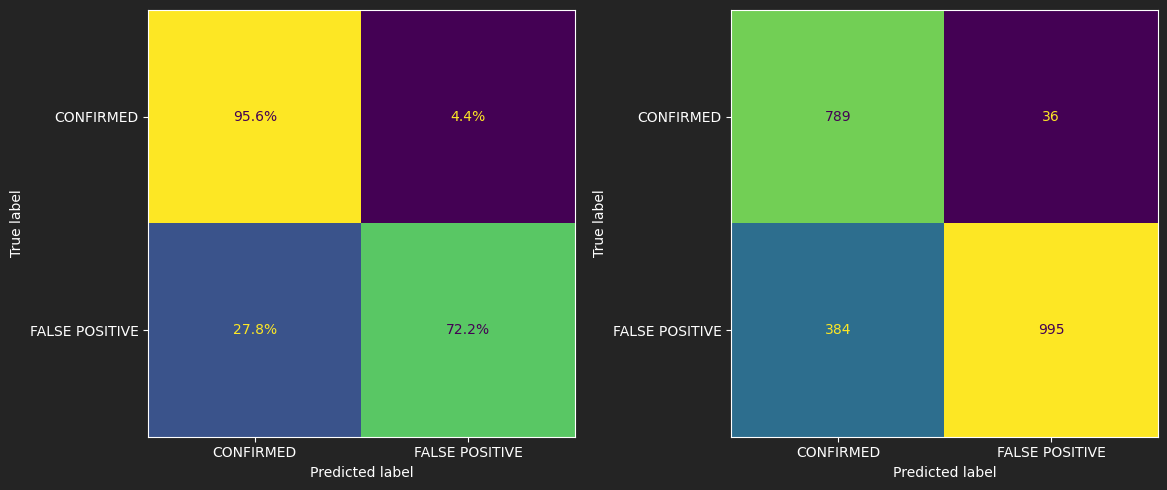

In [184]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
   Y_test, qda_reg.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   normalize="true", values_format=".1%",
   ax=axes[0]
)
ConfusionMatrixDisplay.from_predictions(
   Y_test, qda_reg.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   ax=axes[1]
)
plt.tight_layout();

In [ ]:
# False positives
# "False positive" bodies called confirmed planets by the classifier
f"{((Y_test != qda_reg.predict(X_test))[Y_test == "FALSE POSITIVE"].mean() * 100).round(1)}%"

'27.8%'

In [250]:
# False negatives
# Confirmed planets called "false positives" by the classifier
f"{((Y_test != qda_reg.predict(X_test))[Y_test == "CONFIRMED"].mean() * 100).round(1)}%"

'4.4%'

### Penalized Logistic - L^1^

In [196]:
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegressionCV.html#sklearn.linear_model.LogisticRegressionCV
# set up a pipeline for penalized L1 norm logistic regression
logreg_model_l1 = make_pipeline(
                        StandardScaler(),
                        LogisticRegressionCV(
                            penalty='l1',
                            solver='saga',
                            cv=kf,
                            scoring="accuracy",
                            max_iter=10000))
logreg_model_l1.fit(X_train, Y_train)

display(logreg_model_l1.score(X_train, Y_train))
# cross_val_score(logreg_model_l1, X_train, Y_train,
#                 cv=kf, scoring="accuracy").mean()  # nested CV; not intent

0.8655347384855582

In [197]:
# weird way you have to retrieve the param and CV score from LogisticRegressionCV
lr_cv = logreg_model_l1.named_steps["logisticregressioncv"]

best_C = lr_cv.C_[0]
best_C_index = np.argmin(np.abs(lr_cv.Cs_ - best_C))
fold_scores = next(iter(lr_cv.scores_.values()))
best_cv_score = fold_scores[:, best_C_index].mean()

best_C, best_cv_score

(166.81005372000556, 0.8639759908536586)

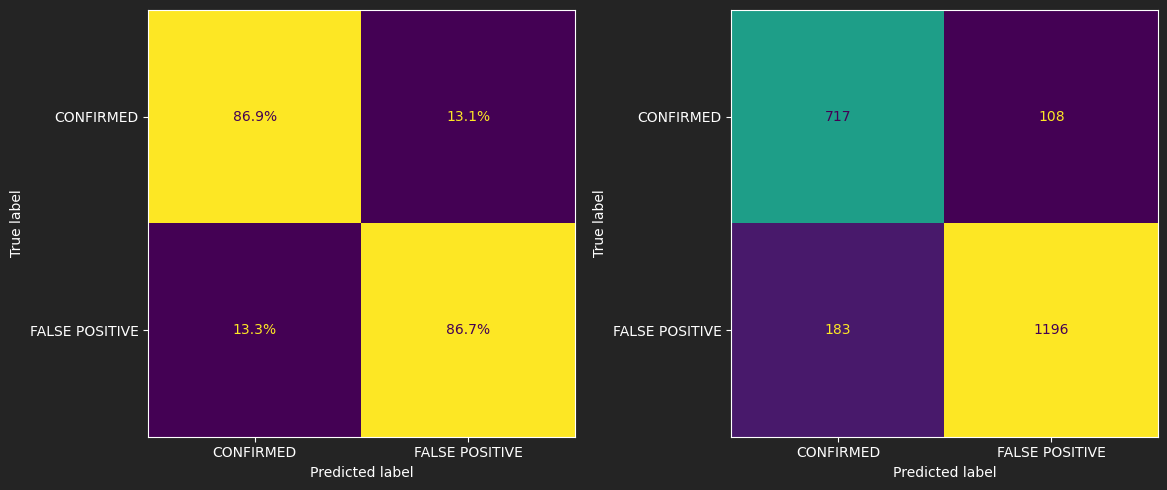

In [198]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
   Y_test, logreg_model_l1.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   normalize="true", values_format=".1%",
   ax=axes[0]
)
ConfusionMatrixDisplay.from_predictions(
   Y_test, logreg_model_l1.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   ax=axes[1]
)
plt.tight_layout();

In [251]:
# False positives
# "False positive" bodies called confirmed planets by the classifier
f"{((Y_test != logreg_model_l1.predict(X_test))[Y_test == "FALSE POSITIVE"].mean() * 100).round(1)}%"

'13.3%'

In [252]:
# False negatives
# Confirmed planets called "false positives" by the classifier
f"{((Y_test != logreg_model_l1.predict(X_test))[Y_test == "CONFIRMED"].mean() * 100).round(1)}%"

'13.1%'

### Penalized Logistic - L^2^

In [187]:
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegressionCV.html#sklearn.linear_model.LogisticRegressionCV
logreg_model_l2 = make_pipeline(
                        StandardScaler(),
                        LogisticRegressionCV(
                            penalty='l2',
                            solver='saga',
                            cv=kf,
                            scoring="accuracy",
                            max_iter=10000))
logreg_model_l2.fit(X_train, Y_train)

display(logreg_model_l2.score(X_train, Y_train))
# cross_val_score(logreg_model_l2, X_train, Y_train,
#                 cv=kf, scoring="accuracy").mean()  # nested CV; not intent

0.8663153786104606

In [195]:
# weird way you have to retrieve the param and CV score from LogisticRegressionCV
lr_cv = logreg_model_l2.named_steps["logisticregressioncv"]

best_C = lr_cv.C_[0]
best_C_index = np.argmin(np.abs(lr_cv.Cs_ - best_C))
fold_scores = next(iter(lr_cv.scores_.values()))
best_cv_score = fold_scores[:, best_C_index].mean()

best_C, best_cv_score

(1291.5496650148827, 0.8633904344512195)

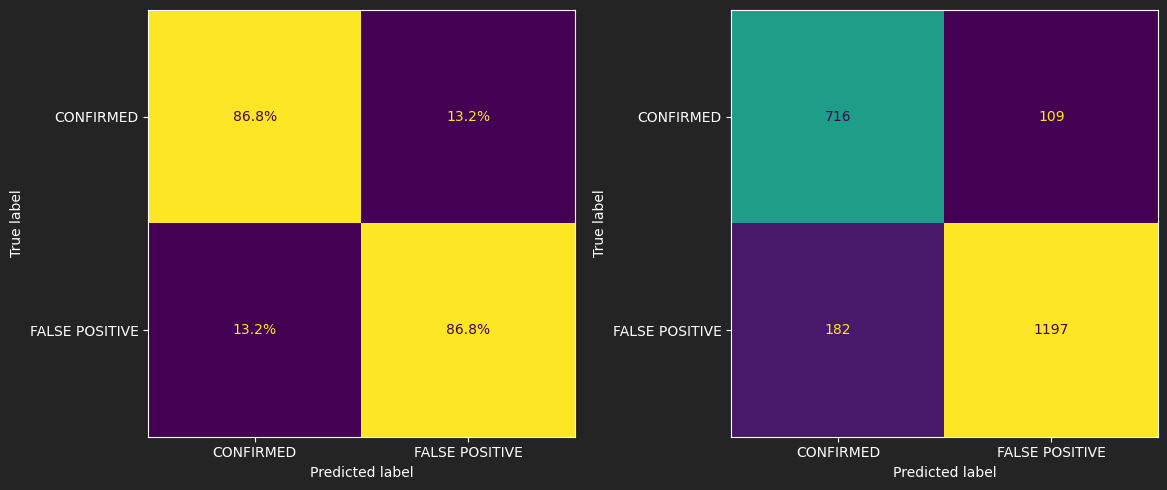

In [186]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
   Y_test, logreg_model_l2.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   normalize="true", values_format=".1%",
   ax=axes[0]
)
ConfusionMatrixDisplay.from_predictions(
   Y_test, logreg_model_l2.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   ax=axes[1]
)
plt.tight_layout();

In [253]:
# False positives
# "False positive" bodies called confirmed planets by the classifier
f"{((Y_test != logreg_model_l2.predict(X_test))[Y_test == "FALSE POSITIVE"].mean() * 100).round(1)}%"

'13.2%'

In [254]:
# False negatives
# Confirmed planets called "false positives" by the classifier
f"{((Y_test != logreg_model_l2.predict(X_test))[Y_test == "CONFIRMED"].mean() * 100).round(1)}%"

'13.2%'

### Decision tree

In [103]:
clf_full_tree = DecisionTreeClassifier(random_state=598)
clf_full_tree.fit(X_train, Y_train);

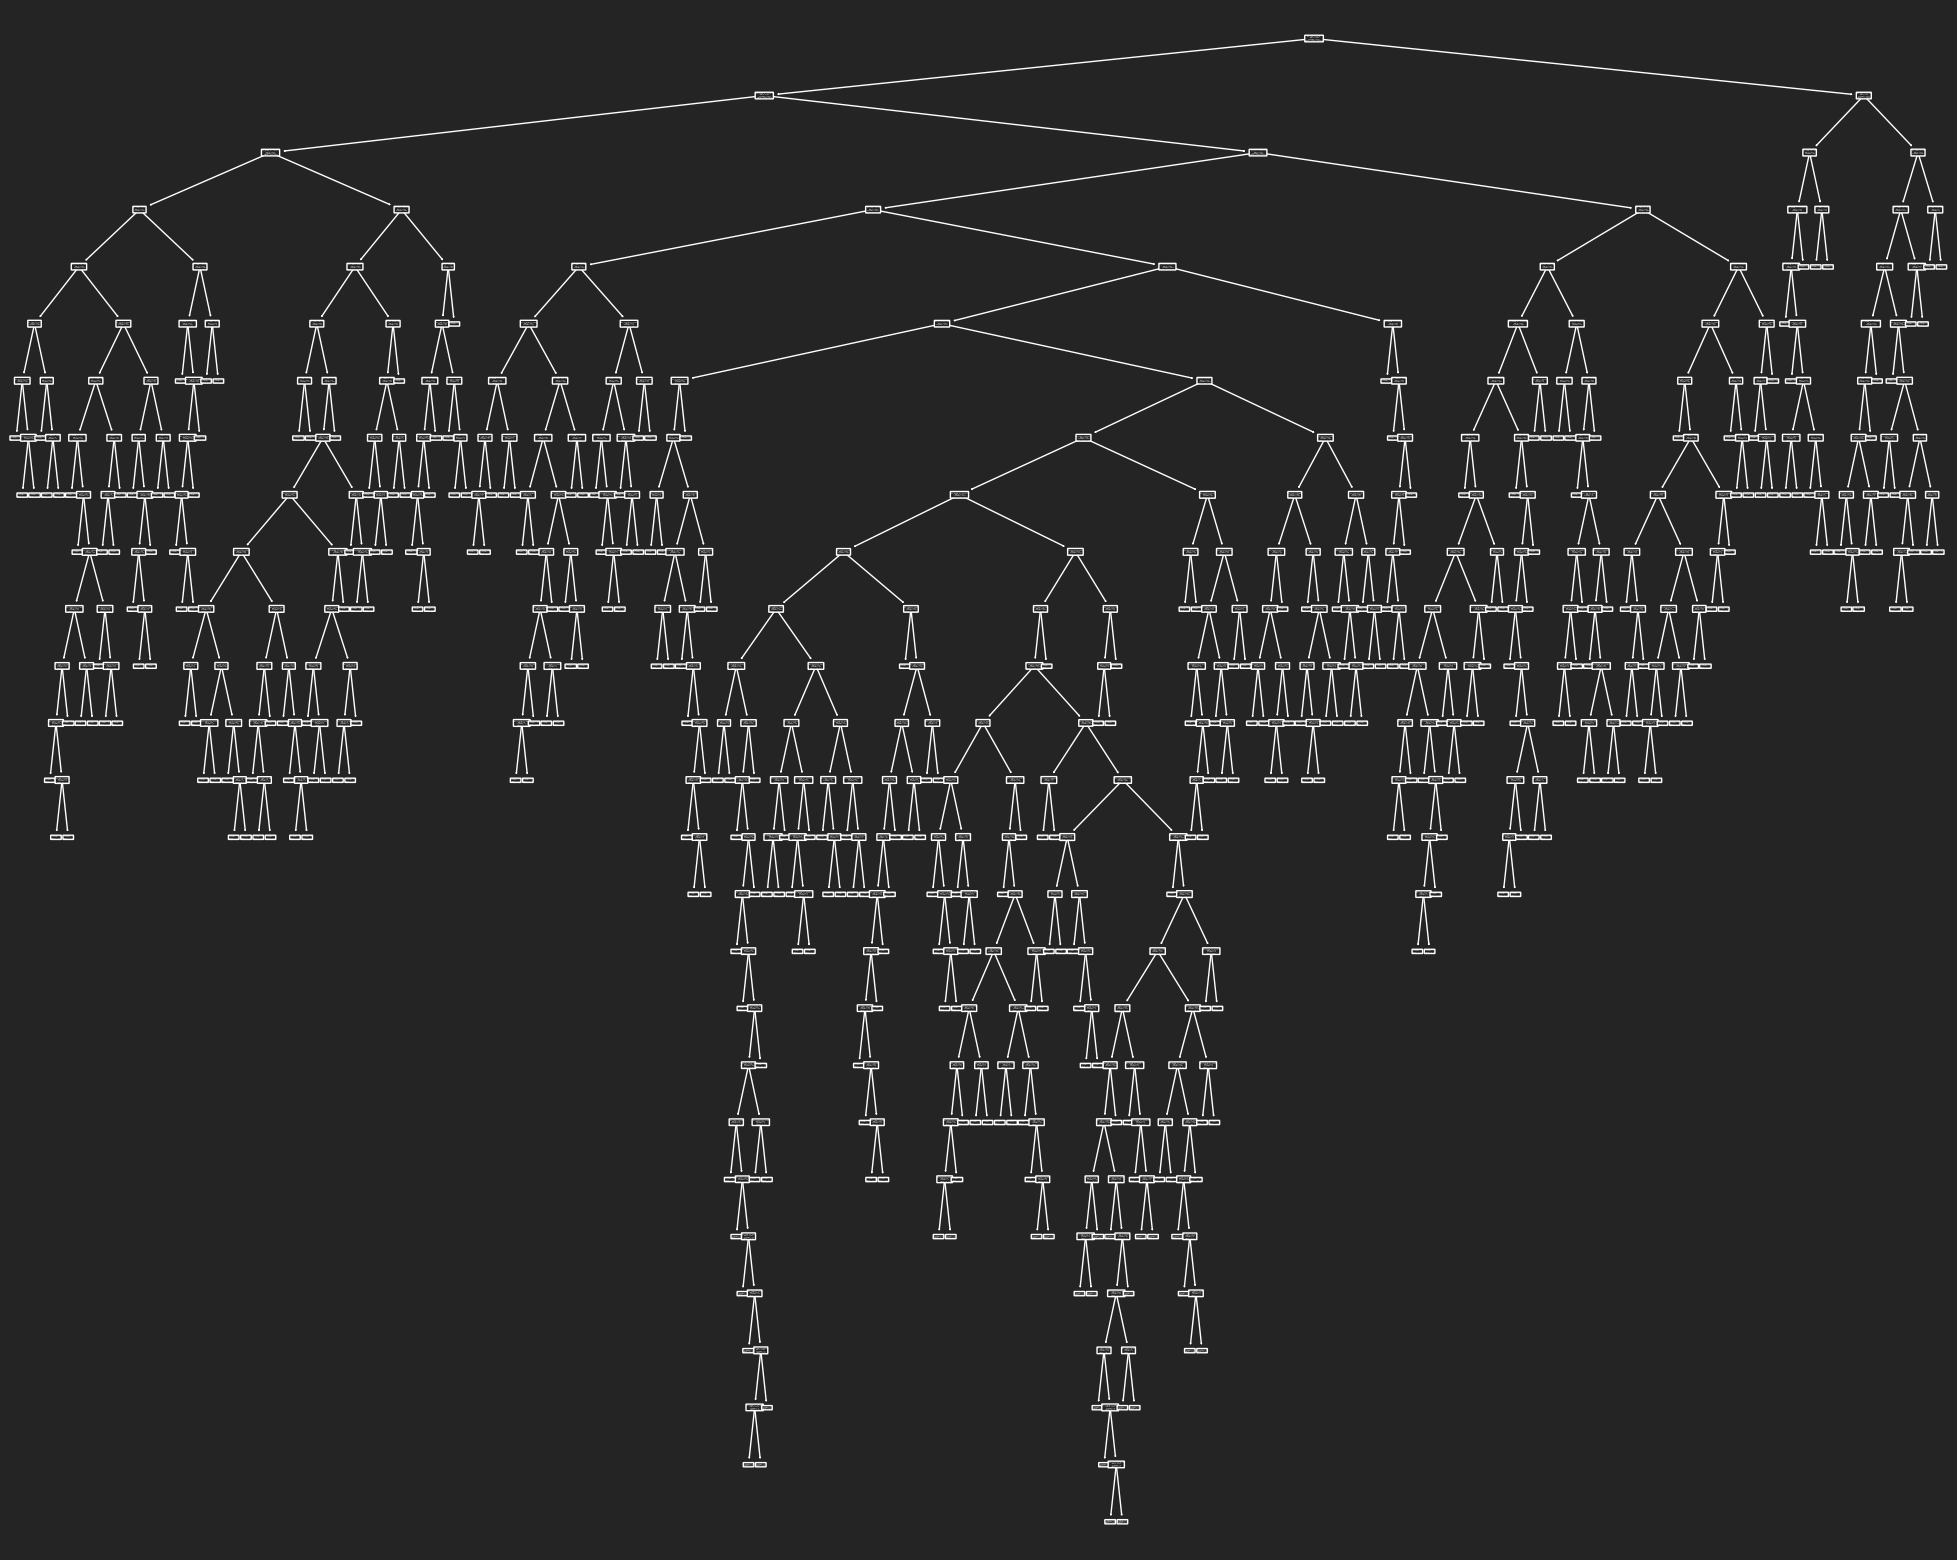

In [ ]:
plt.figure(figsize=(25, 20))
tree.plot_tree(clf_full_tree,
            #  proportion=True,
               feature_names=X_train.columns,
               rounded=True);

#### Cost-complexity pruning (single tree)

In [104]:
path = clf_full_tree.cost_complexity_pruning_path(X_train, Y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

In [ ]:
# Perform cross-validation for different values of ccp_alpha
clfs = []
cv_scores_means = []
for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=598, ccp_alpha=ccp_alpha)
    cv_scores = cross_val_score(clf, X_train, Y_train,
                                cv=kf, scoring="accuracy")
    cv_score_mean = cv_scores.mean()

    clfs.append(clf)
    cv_scores_means.append(cv_score_mean)

# converted to grid search in below section

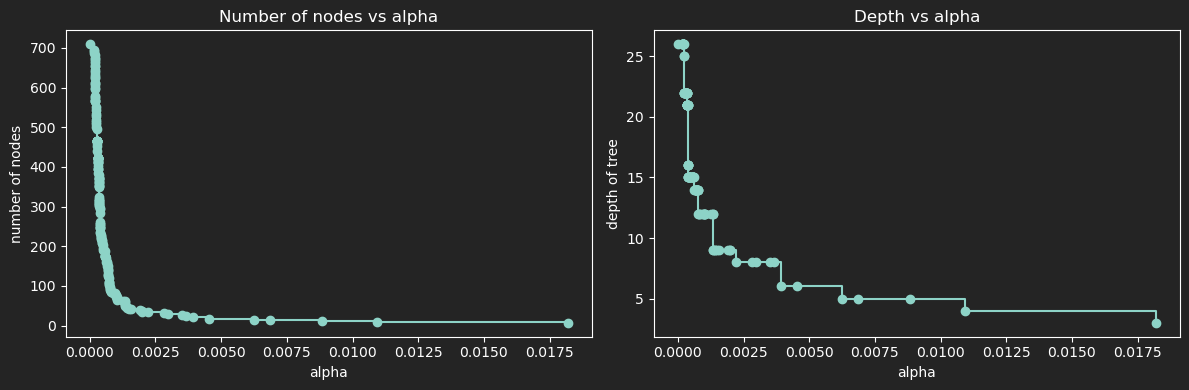

In [223]:
clfs = clfs[:-1]
ccp_alphas = ccp_alphas[:-1]

for clf in clfs:
    clf.fit(X_train, Y_train)

node_counts = [clf.tree_.node_count for clf in clfs]
depth = [clf.tree_.max_depth for clf in clfs]
fig, ax = plt.subplots(1, 2)
fig.set_size_inches(12, 4)
ax[0].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("number of nodes")
ax[0].set_title("Number of nodes vs alpha")
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("depth of tree")
ax[1].set_title("Depth vs alpha")
fig.tight_layout()

In [241]:
# what alpha val was used in the model that produced the best CV accuracy?
# best_index = cv_scores_means.index(max(cv_scores_means))
best_index = np.argmax(cv_scores_means)
best_alpha = ccp_alphas[best_index]; best_alpha

0.0010440000388010975

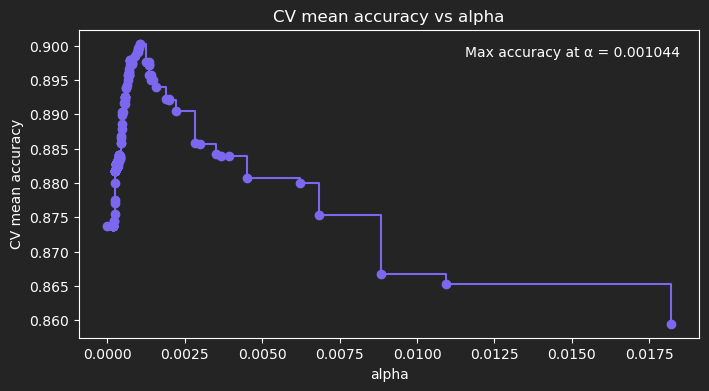

In [ ]:
# plot cv_scores_means vs alpha
plt.figure(figsize=(8, 4))
plt.plot(ccp_alphas, cv_scores_means, marker="o", drawstyle="steps-post", color="mediumslateblue")
plt.xlabel("alpha")
plt.ylabel("CV mean accuracy")
plt.title("CV mean accuracy vs alpha")
plt.annotate(
    f"Max accuracy at α = {ccp_alphas[best_index]:.6g}",
    xy=(0.97, 0.95),
    xycoords="axes fraction",
    ha="right",
    va="top"
);

#### Pruned tree

In [ ]:
# Select best ccp_alpha w/ cross-validation
path = clf_full_tree.cost_complexity_pruning_path(X_train, Y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities
param_grid = {
    'ccp_alpha': ccp_alphas
}
tree_ccpalpha_search = GridSearchCV(
                        DecisionTreeClassifier(random_state=598),
                        param_grid=param_grid,
                        cv=kf,
                        scoring="accuracy")
tree_ccpalpha_search.fit(X_train, Y_train)
display(tree_ccpalpha_search.best_params_)
display(tree_ccpalpha_search.best_score_)
tree_best_alpha = tree_ccpalpha_search.best_estimator_

{'ccp_alpha': 0.0010440000388010975}

0.9002743902439025

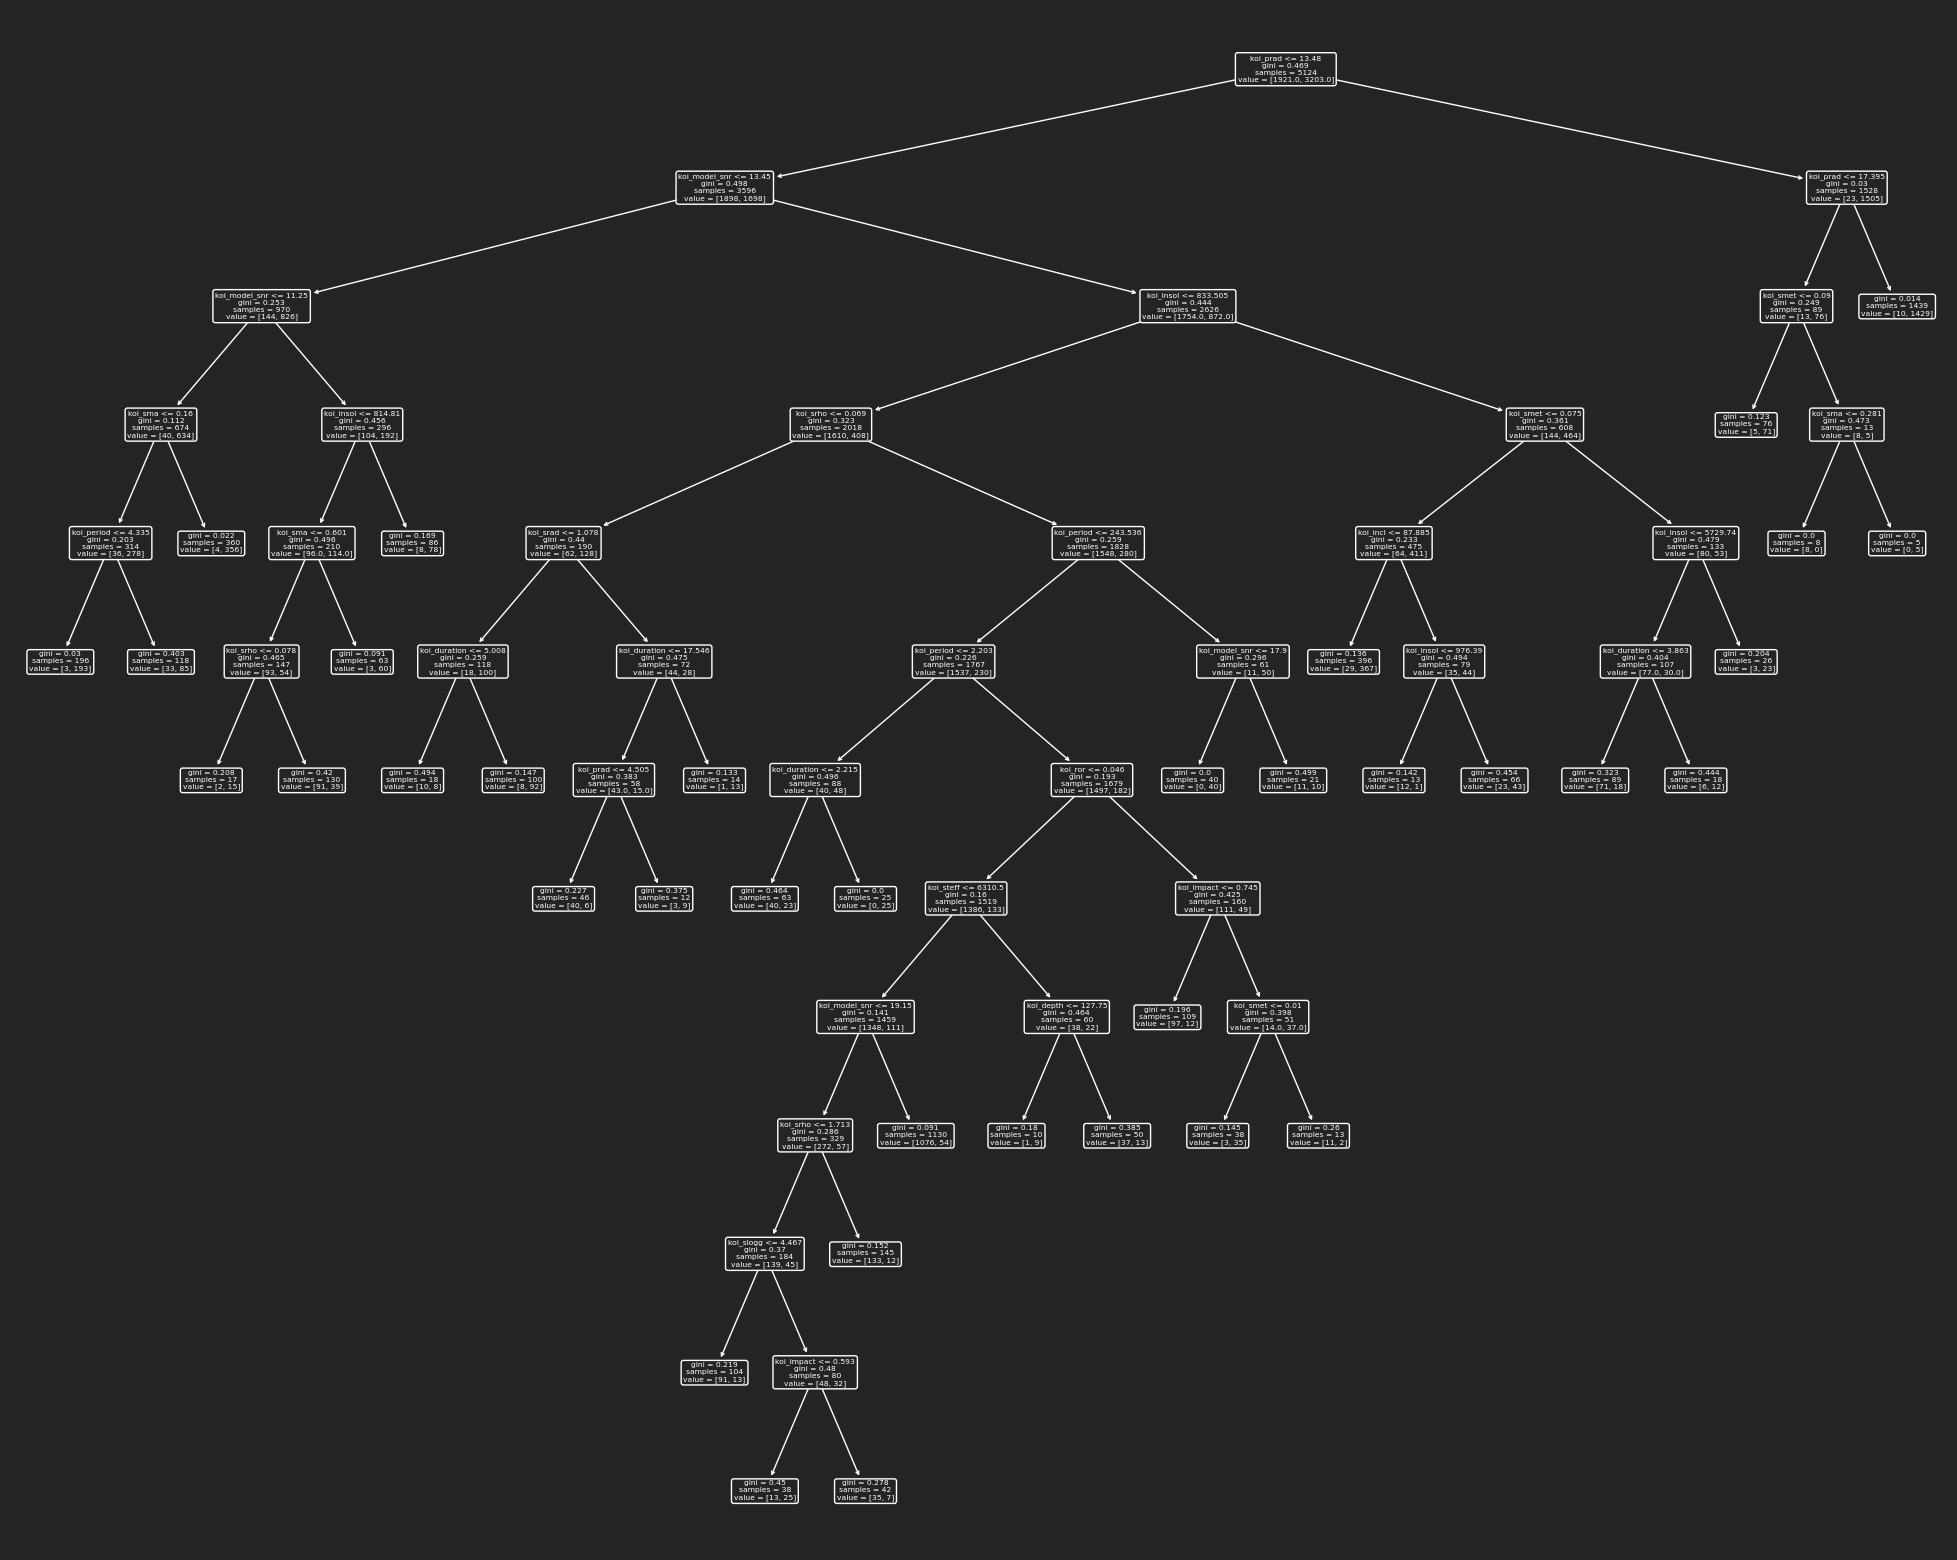

In [210]:
plt.figure(figsize=(25, 20))
tree.plot_tree(tree_best_alpha,
            #  proportion=True,
               feature_names=X_train.columns,
               rounded=True);

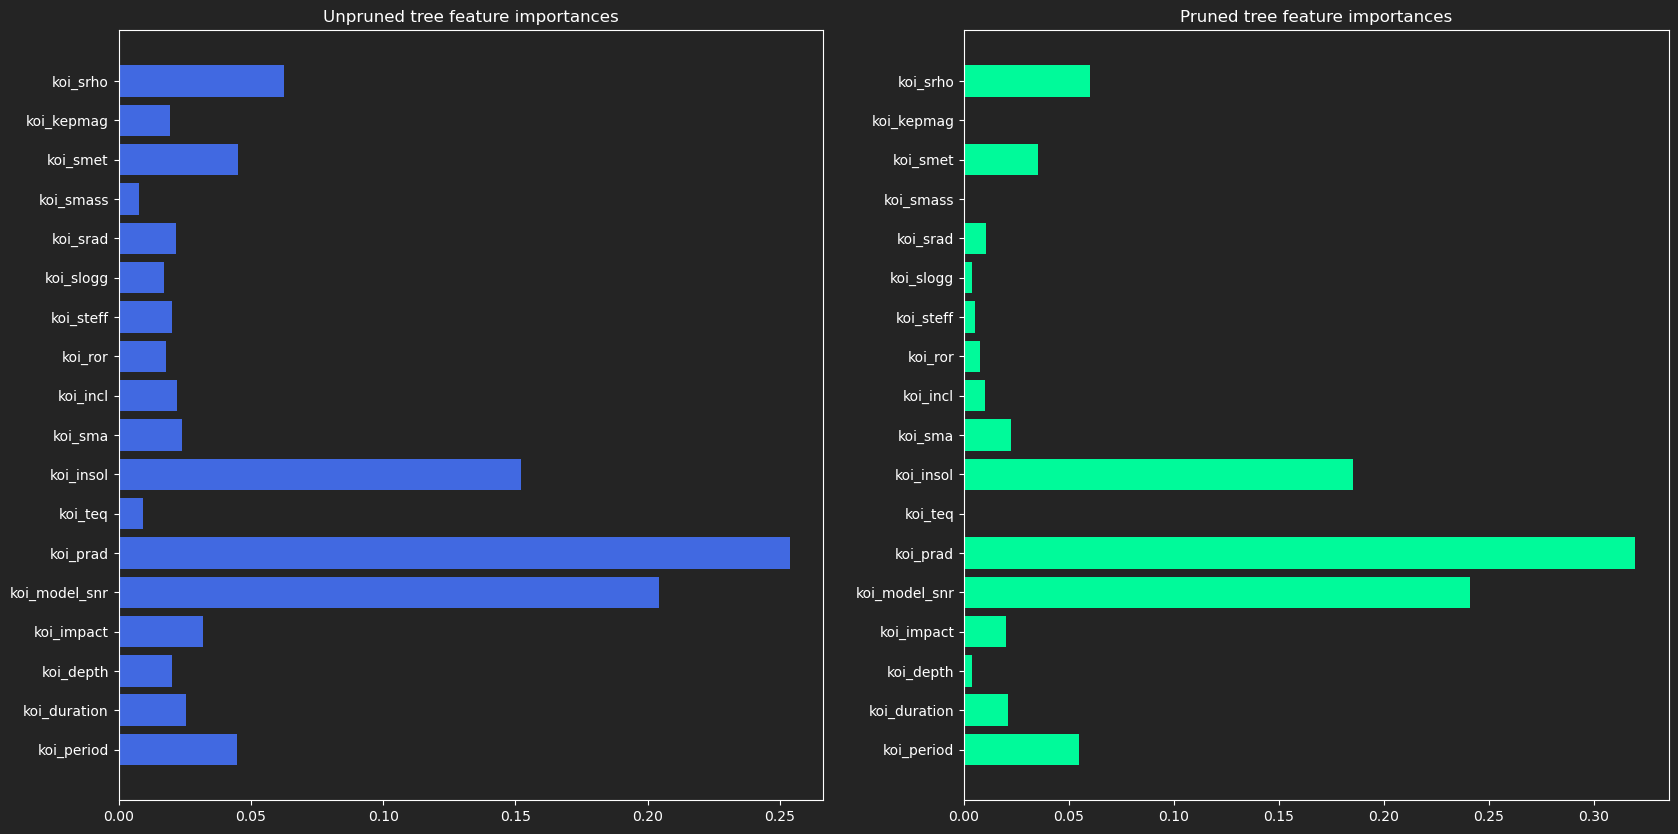

In [ ]:
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(20, 10))

ax_left.barh(X_train.columns, clf_full_tree.feature_importances_, color="royalblue")
ax_left.set_title("Unpruned tree feature importances")
ax_right.set_title("Pruned tree feature importances")
plt.sca(ax_right)
plt.barh(X_train.columns, tree_best_alpha.feature_importances_, color = 'mediumspringgreen');
# tree_best_alpha.feature_importances_

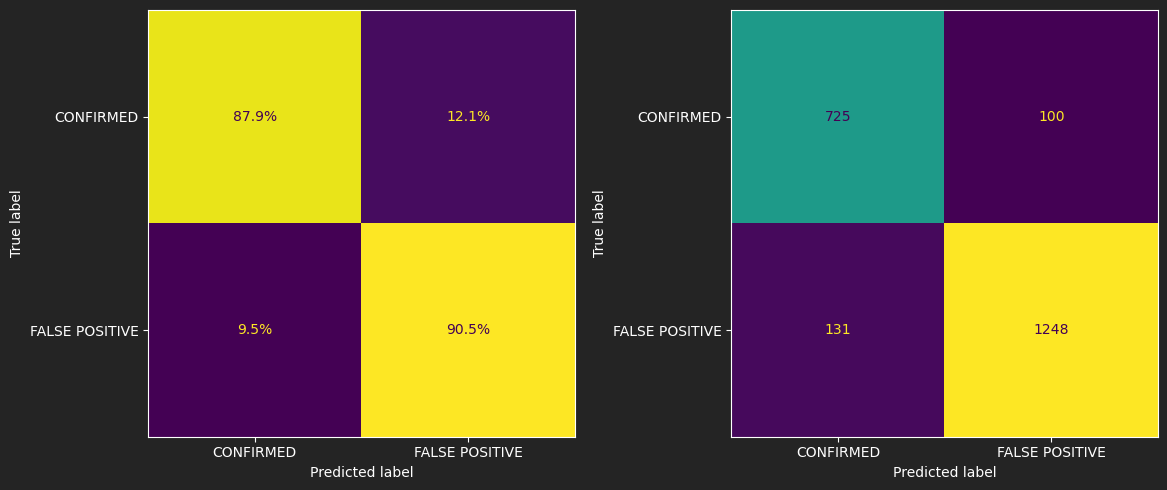

In [217]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
   Y_test, tree_best_alpha.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   normalize="true", values_format=".1%",
   ax=axes[0]
)
ConfusionMatrixDisplay.from_predictions(
   Y_test, tree_best_alpha.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   ax=axes[1]
)
plt.tight_layout();

In [255]:
# False positives
# "False positive" bodies called confirmed planets by the classifier
f"{((Y_test != tree_best_alpha.predict(X_test))[Y_test == "FALSE POSITIVE"].mean() * 100).round(1)}%"

'9.5%'

In [256]:
# False negatives
# Confirmed planets called "false positives" by the classifier
f"{((Y_test != tree_best_alpha.predict(X_test))[Y_test == "CONFIRMED"].mean() * 100).round(1)}%"

'12.1%'

### Tree ensembles

#### Bagging forest

In [99]:
bagging_model = BaggingClassifier(random_state=598,
                                  n_estimators=50,
                                  max_samples=1.0, # use 100% of samples
                                  verbose=1)
bagging_model.fit(X_train, Y_train)

display(bagging_model.score(X_train, Y_train))
cross_val_score(bagging_model, X_train, Y_train,
                cv=kf, scoring="accuracy").mean()

0.9994145199063232

0.9162757240853658

In [ ]:
# train w/ smaller sample sizes, larger number of estimators, and evaluate on out-of-bag samples

In [98]:
bagging_model_tweaked = BaggingClassifier(random_state=598,
                                          oob_score=True,
                                          n_estimators=100,
                                          max_samples=0.8,
                                          verbose=1)
bagging_model_tweaked.fit(X_train, Y_train)

display(bagging_model_tweaked.score(X_train, Y_train))
cross_val_score(bagging_model_tweaked, X_train, Y_train,
                cv=kf, scoring="accuracy").mean()

0.9978532396565184

0.9188134527439026

> generalization error better, but negligible

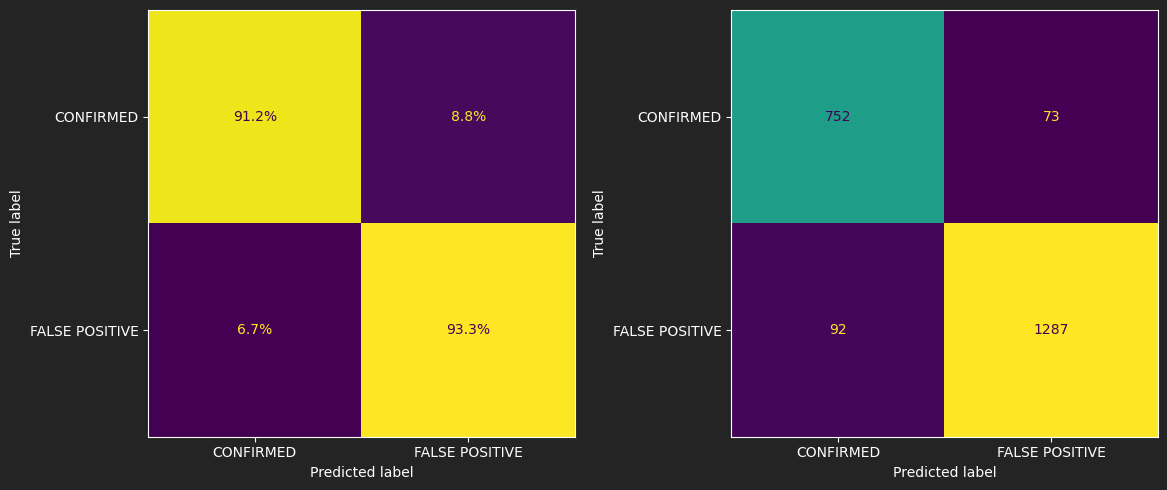

In [126]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
   Y_test, bagging_model.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   normalize="true", values_format=".1%",
   ax=axes[0]
)
ConfusionMatrixDisplay.from_predictions(
   Y_test, bagging_model.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   ax=axes[1]
)
plt.tight_layout();

In [261]:
# False positives
# "False positive" bodies called confirmed planets by the classifier
f"{((Y_test != bagging_model.predict(X_test))[Y_test == "FALSE POSITIVE"].mean() * 100).round(1)}%"

'6.7%'

In [262]:
# False negatives
# Confirmed planets called "false positives" by the classifier
f"{((Y_test != bagging_model.predict(X_test))[Y_test == "CONFIRMED"].mean() * 100).round(1)}%"

'8.8%'

#### Random forest

In [97]:
rf_model = RandomForestClassifier(random_state=598)
rf_model.fit(X_train, Y_train)

display(rf_model.score(X_train, Y_train))
cross_val_score(rf_model, X_train, Y_train,
                cv=kf, scoring="accuracy").mean()

1.0

0.922716844512195

In [199]:
# tune max_features considered at each split, using cross-validation
param_grid = {
    'max_features': [1, 2, 3, 4, 5, 0.33, "log2", "sqrt"]
}
rf_maxfeat_search = GridSearchCV(
                        RandomForestClassifier(random_state=598),
                        param_grid=param_grid,
                        cv=kf,
                        scoring="accuracy")
rf_maxfeat_search.fit(X_train, Y_train)
display(rf_maxfeat_search.best_params_)
display(rf_maxfeat_search.best_score_)
rf_maxfeat = rf_maxfeat_search.best_estimator_

{'max_features': 2}

0.9238889100609757

In [207]:
pd.DataFrame(rf_maxfeat_search.cv_results_)[
    ["param_max_features", "mean_test_score"]
].rename(columns={
    "param_max_features": "max_features",
    "mean_test_score": "CV_mean_accuracy"
})

,max_features,CV_mean_accuracy
0,1,0.919596
1,2,0.923889
2,3,0.922133
3,4,0.922717
4,5,0.923497
5,0.33,0.923497
6,log2,0.922717
7,sqrt,0.922717


> choosing sqrt(p) since there isn't much difference, and I think it will adapt better to new data  
This is the default, but I make it explicit now

In [96]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(random_state=598,
                                  max_features="sqrt")
rf_model.fit(X_train, Y_train)

display(rf_model.score(X_train, Y_train))
cross_val_score(rf_model, X_train, Y_train,
                cv=kf, scoring="accuracy").mean()

1.0

0.922716844512195

In [ ]:
# Now try with more estimators

In [95]:
from sklearn.ensemble import RandomForestClassifier
rf_model_1000 = RandomForestClassifier(random_state=598,
                                       max_features="sqrt",
                                       n_estimators=1000)
rf_model_1000.fit(X_train, Y_train)

display(rf_model_1000.score(X_train, Y_train))
cross_val_score(rf_model_1000, X_train, Y_train,
                cv=kf, scoring="accuracy").mean()

1.0

0.923497713414634

In [ ]:
# with 300 or 1000, accuracy on test set maxes out ~0.9256
# going to set it to 200 as compromise of accuracy and run time

In [94]:
from sklearn.ensemble import RandomForestClassifier
rf_model_200 = RandomForestClassifier(random_state=598,
                                      max_features="sqrt",
                                      n_estimators=200)
rf_model_200.fit(X_train, Y_train)

display(rf_model_200.score(X_train, Y_train))
cross_val_score(rf_model_200, X_train, Y_train,
                cv=kf, scoring="accuracy").mean()

1.0

0.922716844512195

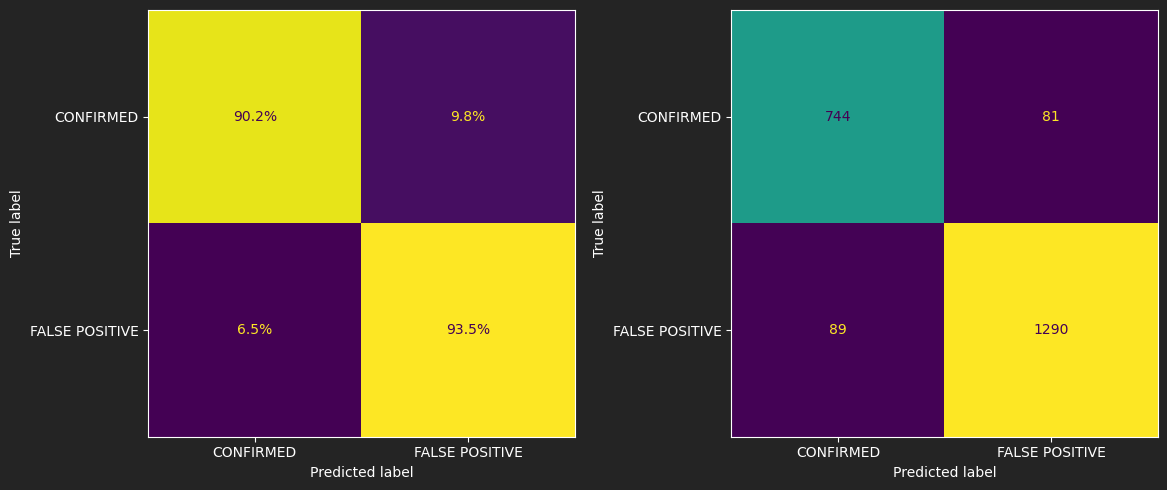

In [218]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
   Y_test, rf_model_200.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   normalize="true", values_format=".1%",
   ax=axes[0]
)
ConfusionMatrixDisplay.from_predictions(
   Y_test, rf_model_200.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   ax=axes[1]
)
plt.tight_layout();

In [263]:
# False positives
# "False positive" bodies called confirmed planets by the classifier
f"{((Y_test != rf_model_200.predict(X_test))[Y_test == "FALSE POSITIVE"].mean() * 100).round(1)}%"

'6.5%'

In [264]:
# False negatives
# Confirmed planets called "false positives" by the classifier
f"{((Y_test != rf_model_200.predict(X_test))[Y_test == "CONFIRMED"].mean() * 100).round(1)}%"

'9.8%'

#### Adaboost

In [75]:
kf = KFold(n_splits=5, shuffle=True, random_state=598)

ada_model = AdaBoostClassifier(random_state=598,
                               algorithm="SAMME")
ada_model.fit(X_train, Y_train)

display(ada_model.score(X_train, Y_train))
cross_val_score(ada_model, X_train, Y_train,
                cv=kf, scoring="accuracy").mean()

0.9014441842310694

0.8916852134146342

In [74]:
# more estimators
ada_model_200 = AdaBoostClassifier(random_state=598,
                                   n_estimators=200,
                                   algorithm="SAMME")
ada_model_200.fit(X_train, Y_train)

display(ada_model_200.score(X_train, Y_train))
cross_val_score(ada_model_200, X_train, Y_train,
                cv=kf, scoring="accuracy").mean()

0.9143247462919594

0.9035905106707318

In [92]:
# tune learning rate with cross validation
lr_grid = {'learning_rate': scipy.stats.loguniform(0.01, 1.0)}  # covers 0.01 to 1.0 from the grid search

ada_base = AdaBoostClassifier(random_state=598,
                              n_estimators=200,
                              algorithm="SAMME")

ada_lr_search = RandomizedSearchCV(
    estimator=ada_base,
    param_distributions=lr_grid,
    n_iter=20,
    cv=kf,
    scoring="accuracy",
    random_state=598,
    n_jobs=2,
    verbose=1,
)
ada_lr_search.fit(X_train, Y_train)
display(ada_lr_search.best_params_)
display(ada_lr_search.best_score_)
ada_lr_optimized = ada_lr_search.best_estimator_

Fitting 5 folds for each of 20 candidates, totalling 100 fits


{'learning_rate': 0.8446765252476186}

0.9063227896341463

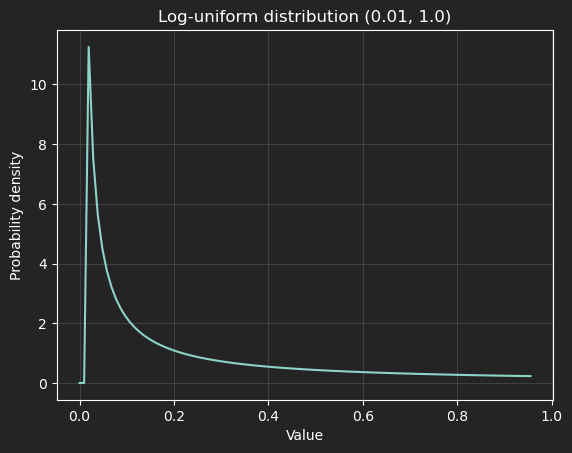

In [91]:
# distribution used for learning-rate hyperparameter search
dist = scipy.stats.loguniform(0.01, 1.0)
x = np.linspace(0, dist.ppf(0.99), 100)

plt.plot(x, dist.pdf(x))
plt.xlabel("Value")
plt.ylabel("Probability density")
plt.title("Log-uniform distribution (0.01, 1.0)")
plt.xscale("log")
plt.grid(True, color='grey', alpha=0.3);
# {'learning_rate': scipy.stats.loguniform(0.01, 1.0)}

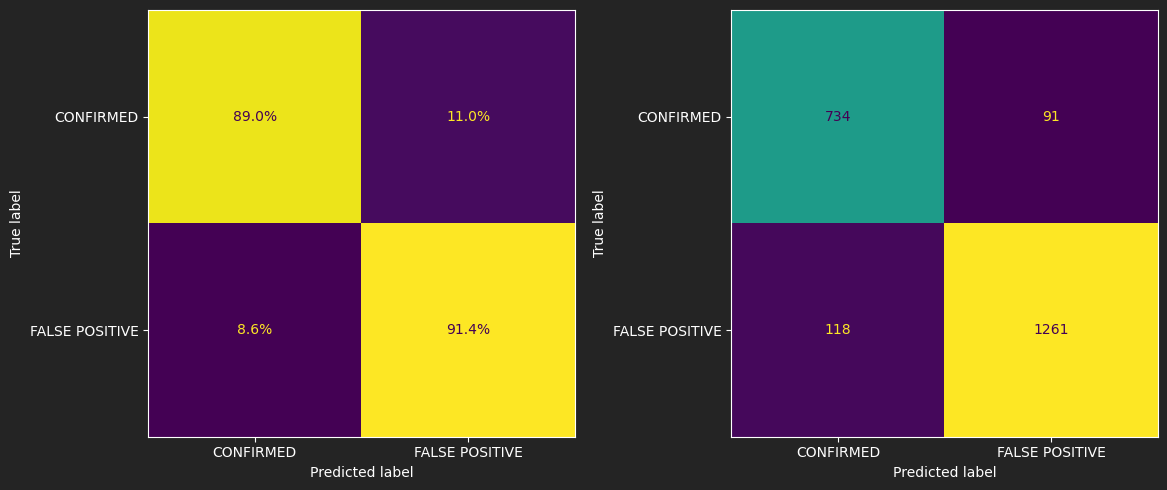

In [219]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
   Y_test, ada_lr_optimized.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   normalize="true", values_format=".1%",
   ax=axes[0]
)
ConfusionMatrixDisplay.from_predictions(
   Y_test, ada_lr_optimized.predict(X_test),
   labels=np.array(["CONFIRMED", "FALSE POSITIVE"]),
   colorbar=False,
   ax=axes[1]
)
plt.tight_layout();

In [265]:
# False positives
# "False positive" bodies called confirmed planets by the classifier
f"{((Y_test != ada_lr_optimized.predict(X_test))[Y_test == "FALSE POSITIVE"].mean() * 100).round(1)}%"

'8.6%'

In [266]:
# False negatives
# Confirmed planets called "false positives" by the classifier
f"{((Y_test != ada_lr_optimized.predict(X_test))[Y_test == "CONFIRMED"].mean() * 100).round(1)}%"

'11.0%'

#### Gradient boosting

In [ ]:
gb_model = GradientBoostingClassifier(random_state=598)
gb_model.fit(X_train, Y_train)
gb_model.score(X_train, Y_train)

0.9416471506635441

In [166]:
gb_model.score(X_test, Y_test)

0.926497277676951

In [ ]:
# tune the learning rate with cross-validation

gb_model_300 = GradientBoostingClassifier(random_state=598,
                                          n_estimators=300)
gb_model_300.fit(X_train, Y_train)
gb_model_300.score(X_train, Y_train)

0.9771662763466042

In [ ]:
# integrate this from CA3

kf = KFold(n_splits=5, shuffle=True, random_state=597)

tree_counts = [10, 25, 50, 100, 150, 200, 250, 300, 400, 500, 700, 850, 1000]
cv_mses_gbr = []
for count in tree_counts:
    gbr = GradientBoostingRegressor(random_state=597, n_estimators=count, learning_rate=0.1)
    cv_scores = cross_val_score(gbr, X_train_enc, Y_train,
                                cv=kf, scoring="neg_mean_squared_error" )
    cv_mses_gbr.append(-cv_scores.mean())

In [ ]:
pd.DataFrame({"trees": tree_counts, "MSE_avg_CV": cv_mses_gbr})
